# Tugas Besar 2 Artifisial Intelejen

## Pendahuluan
Pada tugas besar ini kita disuruh untuk melakukan prediksi pembatalan pemesanan dari sebuah data bookingan suatu kamar hotel.

## Import dan Konfigurasi

In [1]:
import os
import sys
import time
import random
import pickle
import warnings
from pathlib import Path
import pandas as pd
# Locate the repository before importing its local SVM package.
_NOTEBOOK_ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / 'src' / 'models' / 'svm').is_dir()
)
if str(_NOTEBOOK_ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(_NOTEBOOK_ROOT / 'src'))
from models.svm import SVM
from models import LogisticRegressionClassifier
from sklearn.metrics import log_loss
from sklearn import __version__ as sklearn_version
from models.svm.visualization import plot_svm_boundary
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation   
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler, MinMaxScaler, OneHotEncoder, OrdinalEncoder, LabelEncoder
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, mutual_info_classif, chi2
from sklearn.decomposition import PCA
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, StratifiedGroupKFold, cross_val_score, GridSearchCV
)
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report,
    RocCurveDisplay
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree   # ID3/C4.5/CART 
from sklearn.linear_model import LogisticRegression         
from sklearn.svm import SVC                                 
from sklearn.naive_bayes import GaussianNB, CategoricalNB
from scipy.stats import chi2_contingency


In [2]:
#Konfigurasi untuk menampilkan semua peringatan
#Menentukan nilai seed untuk memastikan hasil yang konsisten
SEED = 42
#Mengatur seed untuk berbagai pustaka yang digunakan dalam kode ini
random.seed(SEED)
np.random.seed(SEED)

#Mengatur ROOT path
ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / 'data' / 'train.csv').exists())
DATA_DIR = ROOT / "data"
OUTPUT_DIR = ROOT / "output"
print(f"Root path: {ROOT}")
print(f"Data directory: {DATA_DIR}")
print(f"Output directory: {OUTPUT_DIR}")


Root path: D:\proyek\IF3170_G14_LalapKaoBole
Data directory: D:\proyek\IF3170_G14_LalapKaoBole\data
Output directory: D:\proyek\IF3170_G14_LalapKaoBole\output


## Load Data

In [3]:
train_file = DATA_DIR / "train.csv"
test_file = DATA_DIR / "test.csv"
train_df = pd.read_csv(train_file)
test_df = pd.read_csv(test_file)

## Exploratory Data Analysis
Pada tahap ini dicari tahu distribusi nilai suatu atribut, statistik setiap atribut yang ada, dan statistik missing values yang ada. 

### 1. Gambaran Umum

In [4]:
#Gambaran umum tentang dataset
print("Dataset Overview:")
train_df.info()
train_df.describe(include='all')

Dataset Overview:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27373 entries, 0 to 27372
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   id                        27373 non-null  object 
 1   num_adults                26564 non-null  float64
 2   num_children              24338 non-null  float64
 3   weekend_nights            27373 non-null  int64  
 4   weekday_nights            27373 non-null  int64  
 5   meal_package              25613 non-null  object 
 6   needs_parking             26291 non-null  float64
 7   room_category             26371 non-null  object 
 8   days_before_arrival       26250 non-null  float64
 9   arrival_year              27373 non-null  int64  
 10  arrival_month             27373 non-null  int64  
 11  arrival_day               27373 non-null  int64  
 12  booking_channel           27373 non-null  object 
 13  is_returning_guest        27373 non-null  i

,id,num_adults,num_children,weekend_nights,weekday_nights,meal_package,needs_parking,room_category,days_before_arrival,arrival_year,arrival_month,arrival_day,booking_channel,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,is_canceled
count,27373,26564.000000,24338.000000,27373.000000,27373.000000,25613,26291.000000,26371,26250.000000,27373.000000,27373.000000,27373.000000,27373,27373.000000,27373.000000,27373.000000,2.533500e+04,24873.000000,27373.000000
unique,27373,NaN,NaN,NaN,NaN,4,NaN,7,NaN,NaN,NaN,NaN,5,NaN,NaN,NaN,NaN,NaN,NaN
top,57152f82,NaN,NaN,NaN,NaN,Breakfast,NaN,Type B,NaN,NaN,NaN,NaN,Online Travel Agent,NaN,NaN,NaN,NaN,NaN,NaN
freq,1,NaN,NaN,NaN,NaN,19654,NaN,20447,NaN,NaN,NaN,NaN,17511,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,1.845242,0.117388,0.814854,2.206517,NaN,0.030200,NaN,85.379429,2023.820115,7.399664,15.537537,NaN,0.025171,0.021883,0.144887,1.716980e+06,0.666948,0.327659
std,NaN,0.517974,0.425761,0.875146,1.421603,NaN,0.171142,NaN,85.969638,0.384099,3.074788,8.773321,NaN,0.156646,0.356353,1.693652,5.879368e+05,0.798363,0.469368
min,NaN,0.000000,0.000000,0.000000,0.000000,NaN,0.000000,NaN,0.000000,2023.000000,1.000000,1.000000,NaN,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000
25%,NaN,2.000000,0.000000,0.000000,1.000000,NaN,0.000000,NaN,17.000000,2024.000000,5.000000,8.000000,NaN,0.000000,0.000000,0.000000,1.338000e+06,0.000000,0.000000
50%,NaN,2.000000,0.000000,1.000000,2.000000,NaN,0.000000,NaN,58.000000,2024.000000,8.000000,16.000000,NaN,0.000000,0.000000,0.000000,1.644000e+06,0.000000,0.000000
75%,NaN,2.000000,0.000000,2.000000,3.000000,NaN,0.000000,NaN,126.000000,2024.000000,10.000000,23.000000,NaN,0.000000,0.000000,0.000000,2.019000e+06,1.000000,1.000000


#### Insight
- Data training berisi 27.373 booking dengan 17 fitur, terdiri atas 14 fitur numerik dan 3 fitur kategorikal. Kolom id tidak dipakai karena hanya berisi kode unik.
- Skala fitur sangat berbeda. nightly_rate_idr bernilai jutaan, sedangkan fitur lain kebanyakan di bawah 20. Model seperti KNN, SVM, dan Logistic Regression perlu scaling terlebih dahulu.

### 2. Distribusi Target

In [5]:
target_counts = train_df['is_canceled'].value_counts()
print("Target Variable Distribution:")
print(target_counts)

Target Variable Distribution:
is_canceled
0    18404
1     8969
Name: count, dtype: int64


#### Insight
- Sekitar 67% booking tidak dibatalkan dan 33% dibatalkan.
- Model yang selalu menebak "tidak batal" sudah mendapat accuracy 67%, jadi evaluasi perlu memakai metrik lain seperti F1 dan ROC AUC.

### 3. Missing Values

In [6]:
# Missing values
missing_val_per_col = {col: train_df[col].isnull().sum() for col in train_df.columns}
for col, missing_count in missing_val_per_col.items():
    if missing_count > 0:
        print(f"Column '{col}' has {missing_count} missing values.")

Column 'num_adults' has 809 missing values.
Column 'num_children' has 3035 missing values.
Column 'meal_package' has 1760 missing values.
Column 'needs_parking' has 1082 missing values.
Column 'room_category' has 1002 missing values.
Column 'days_before_arrival' has 1123 missing values.
Column 'nightly_rate_idr' has 2038 missing values.
Column 'special_requests' has 2500 missing values.


#### Insight
- Delapan kolom memiliki nilai kosong, paling banyak pada num_children (11%). Kolom lain kosong kurang dari 10%.
- Sekitar 39% baris memiliki minimal satu nilai kosong, sehingga menghapus baris akan membuang terlalu banyak data. Nilai kosong lebih baik diisi dengan median untuk fitur numerik dan modus untuk fitur kategorikal.

### 4. Data duplikat dan tidak valid

In [7]:
duplicate_rows = train_df[train_df.duplicated()]
print(f"Number of duplicate rows in the training dataset: {len(duplicate_rows)}")

Number of duplicate rows in the training dataset: 0


In [8]:
unused_features = ['id', 'is_canceled']

#### Insight
- Tidak ada baris duplikat. Namun, jika id diabaikan, ada 64 baris yang isinya sama persis dengan baris lain. Baris seperti ini perlu dijaga agar tidak masuk ke training dan validation sekaligus.
- Tarif 0 pada 413 booking bukan kesalahan data karena sebagian besar berasal dari kanal Complimentary.

### 5. Fitur numerik

In [9]:
#Fitur numerik minus target dan id
numeric_features = train_df.select_dtypes(include=['int64', 'float64']).columns.tolist()
numeric_features = [col for col in numeric_features if col not in unused_features]
print(f"Numeric features: {numeric_features}")


Numeric features: ['num_adults', 'num_children', 'weekend_nights', 'weekday_nights', 'needs_parking', 'days_before_arrival', 'arrival_year', 'arrival_month', 'arrival_day', 'is_returning_guest', 'prior_cancellations', 'prior_completed_bookings', 'nightly_rate_idr', 'special_requests']



Feature: num_adults
count    26564.000000
mean         1.845242
std          0.517974
min          0.000000
25%          2.000000
50%          2.000000
75%          2.000000
max          4.000000
Name: num_adults, dtype: float64


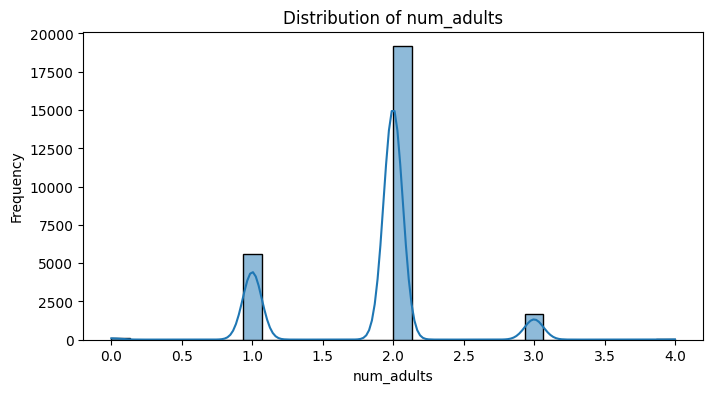


Feature: num_children
count    24338.000000
mean         0.117388
std          0.425761
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max         10.000000
Name: num_children, dtype: float64


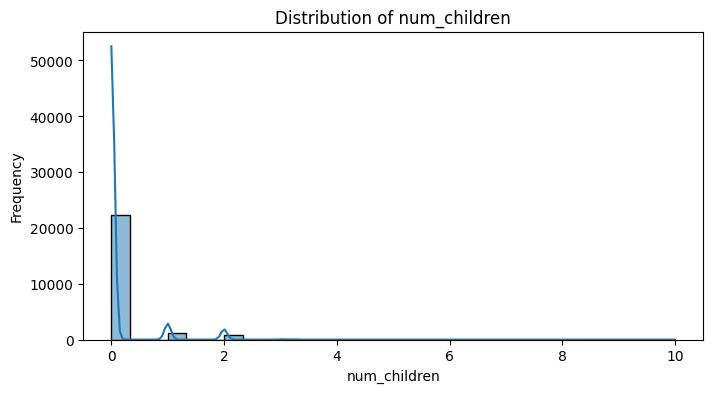


Feature: weekend_nights
count    27373.000000
mean         0.814854
std          0.875146
min          0.000000
25%          0.000000
50%          1.000000
75%          2.000000
max          7.000000
Name: weekend_nights, dtype: float64


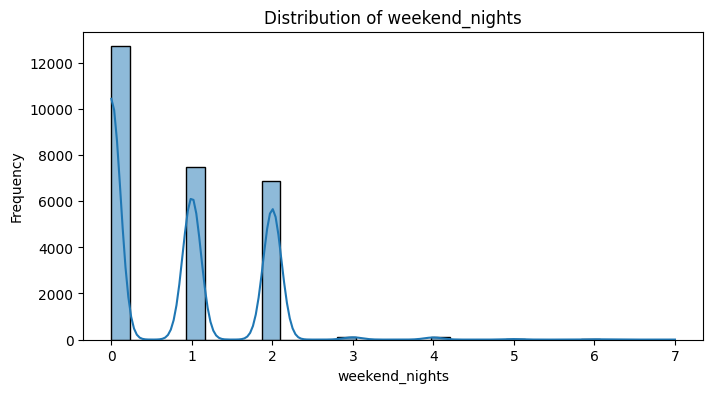


Feature: weekday_nights
count    27373.000000
mean         2.206517
std          1.421603
min          0.000000
25%          1.000000
50%          2.000000
75%          3.000000
max         17.000000
Name: weekday_nights, dtype: float64


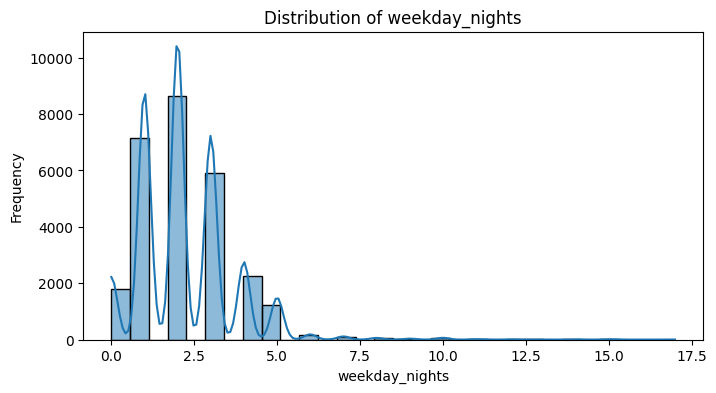


Feature: needs_parking
count    26291.000000
mean         0.030200
std          0.171142
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max          1.000000
Name: needs_parking, dtype: float64


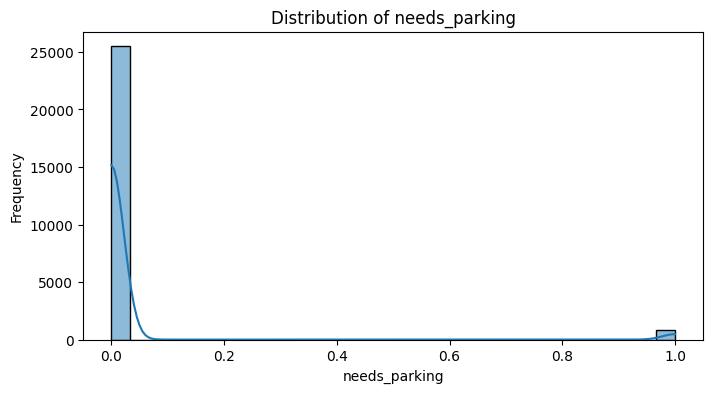


Feature: days_before_arrival
count    26250.000000
mean        85.379429
std         85.969638
min          0.000000
25%         17.000000
50%         58.000000
75%        126.000000
max        448.000000
Name: days_before_arrival, dtype: float64


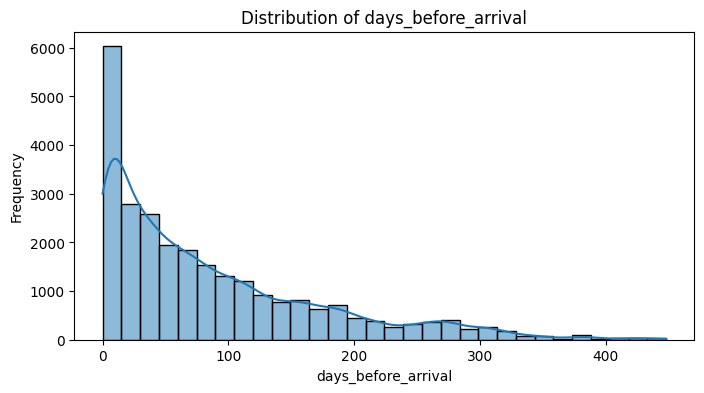


Feature: arrival_year
count    27373.000000
mean      2023.820115
std          0.384099
min       2023.000000
25%       2024.000000
50%       2024.000000
75%       2024.000000
max       2024.000000
Name: arrival_year, dtype: float64


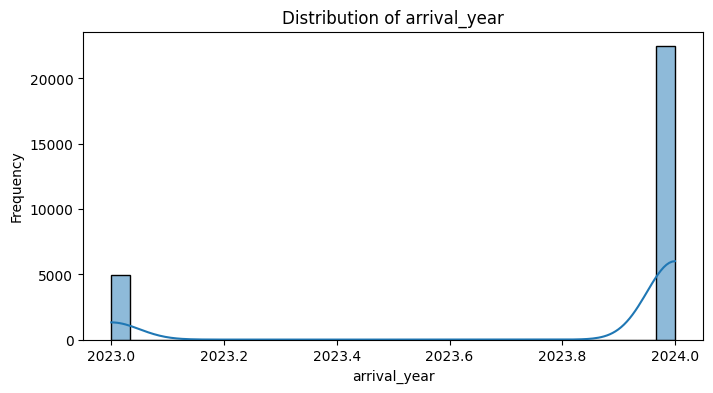


Feature: arrival_month
count    27373.000000
mean         7.399664
std          3.074788
min          1.000000
25%          5.000000
50%          8.000000
75%         10.000000
max         12.000000
Name: arrival_month, dtype: float64


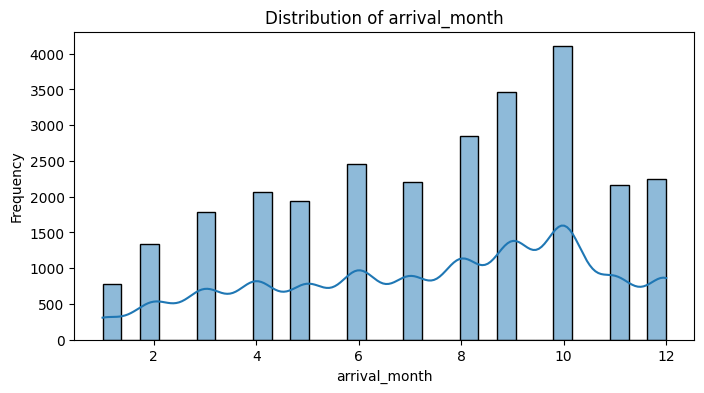


Feature: arrival_day
count    27373.000000
mean        15.537537
std          8.773321
min          1.000000
25%          8.000000
50%         16.000000
75%         23.000000
max         31.000000
Name: arrival_day, dtype: float64


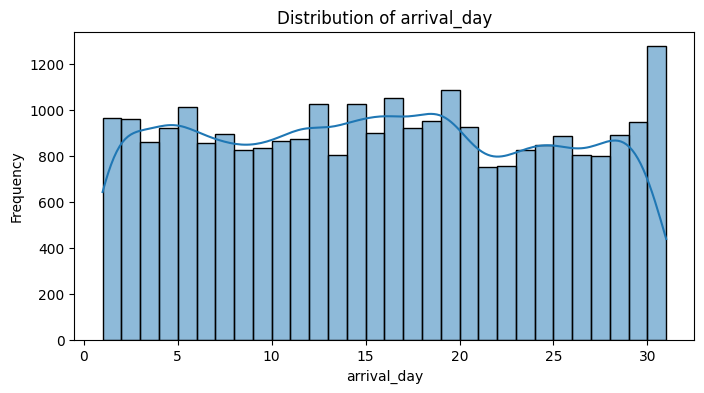


Feature: is_returning_guest
count    27373.000000
mean         0.025171
std          0.156646
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max          1.000000
Name: is_returning_guest, dtype: float64


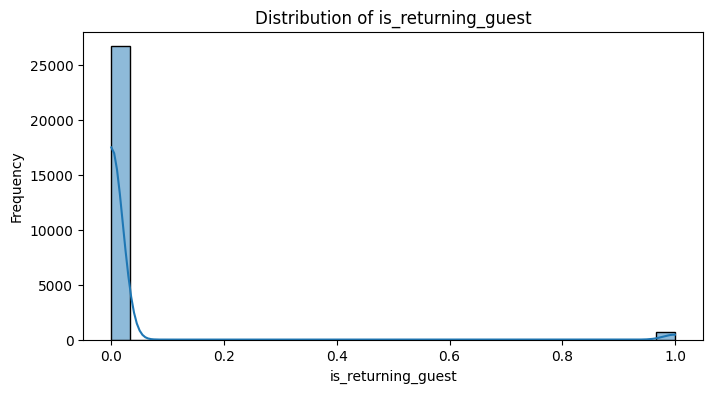


Feature: prior_cancellations
count    27373.000000
mean         0.021883
std          0.356353
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max         13.000000
Name: prior_cancellations, dtype: float64


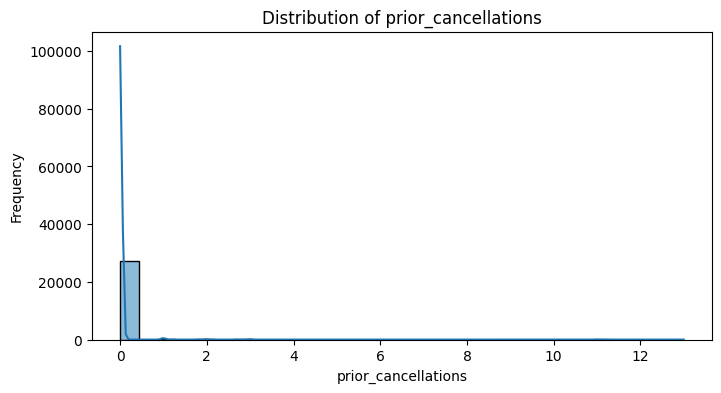


Feature: prior_completed_bookings
count    27373.000000
mean         0.144887
std          1.693652
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max         58.000000
Name: prior_completed_bookings, dtype: float64


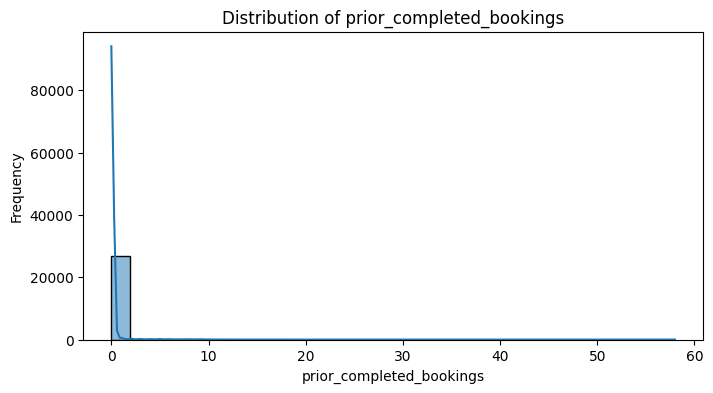


Feature: nightly_rate_idr
count    2.533500e+04
mean     1.716980e+06
std      5.879368e+05
min      0.000000e+00
25%      1.338000e+06
50%      1.644000e+06
75%      2.019000e+06
max      9.165000e+06
Name: nightly_rate_idr, dtype: float64


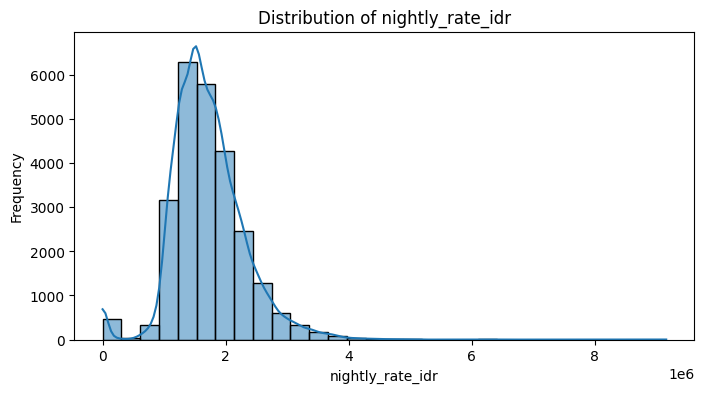


Feature: special_requests
count    24873.000000
mean         0.666948
std          0.798363
min          0.000000
25%          0.000000
50%          0.000000
75%          1.000000
max          5.000000
Name: special_requests, dtype: float64


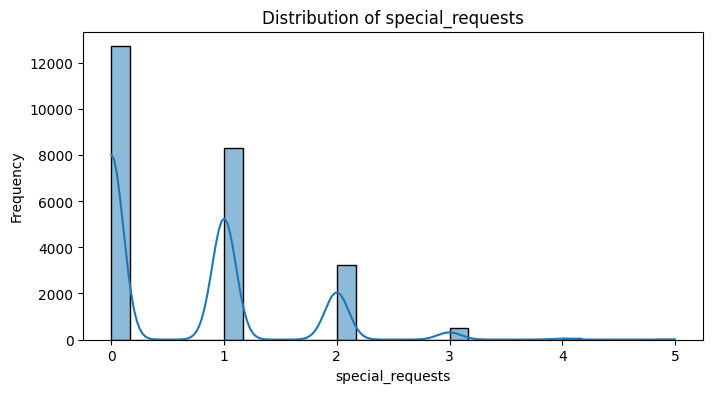

In [10]:
# Statistik deskriptif untuk fitur numerik dan histogram distribusi
for feature in numeric_features:
    print(f"\nFeature: {feature}")
    print(train_df[feature].describe())
    plt.figure(figsize=(8, 4))
    sns.histplot(train_df[feature], kde=True, bins=30)
    plt.title(f'Distribution of {feature}')
    plt.xlabel(feature)
    plt.ylabel('Frequency')
    plt.show()

#### Insight
- Beberapa fitur hampir selalu bernilai 0, yaitu needs_parking, is_returning_guest, prior_cancellations, dan prior_completed_bookings. Informasinya hanya ada pada sebagian kecil booking.
- days_before_arrival miring ke kanan. Sebagian besar booking dibuat paling lama sekitar 4 bulan sebelum kedatangan, tetapi ada yang sampai 448 hari.

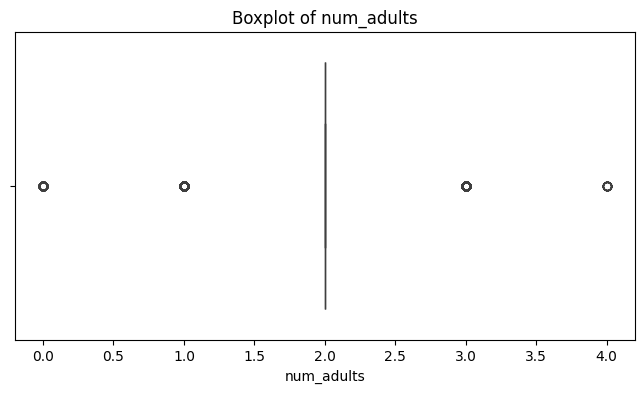

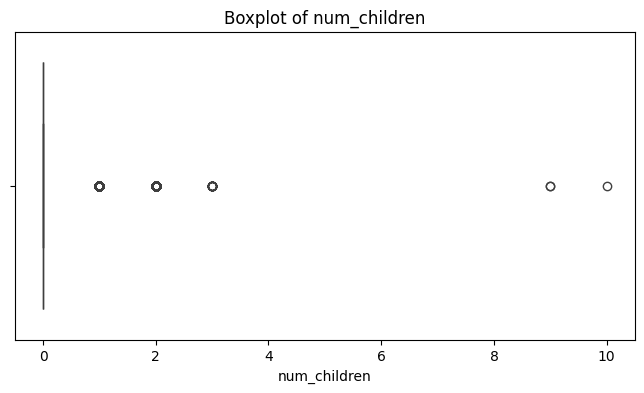

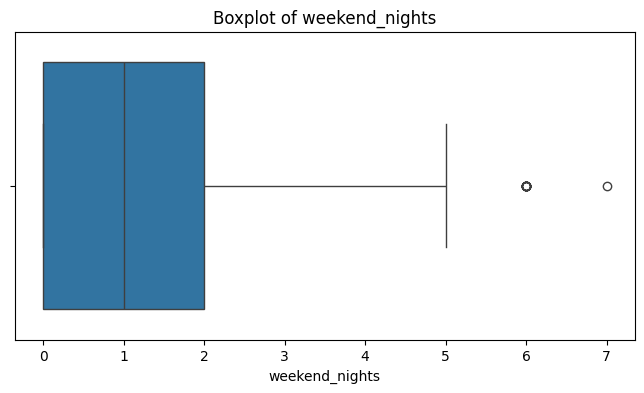

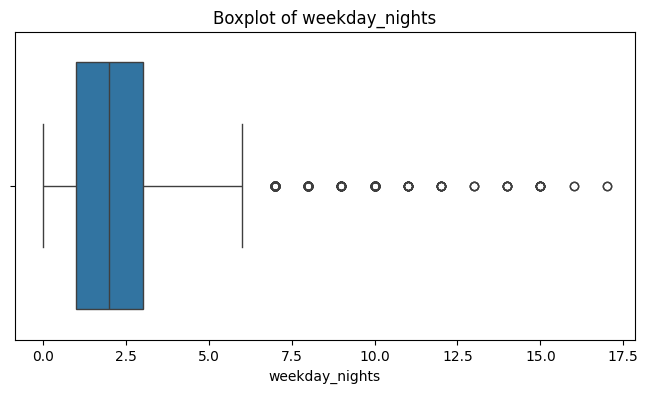

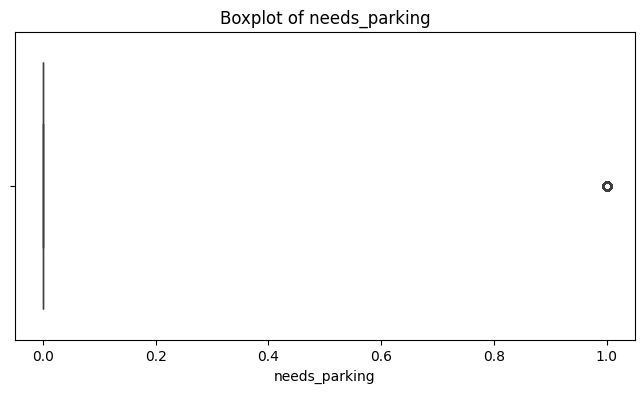

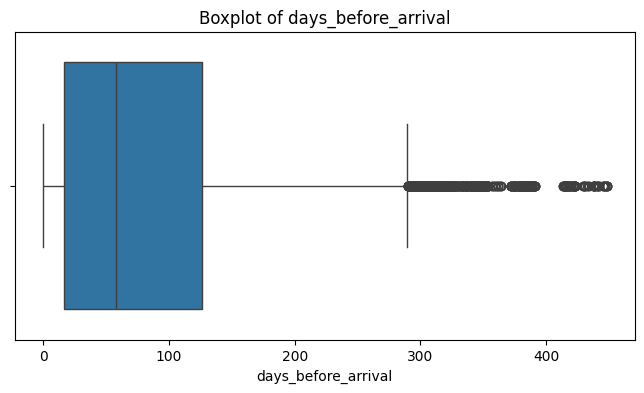

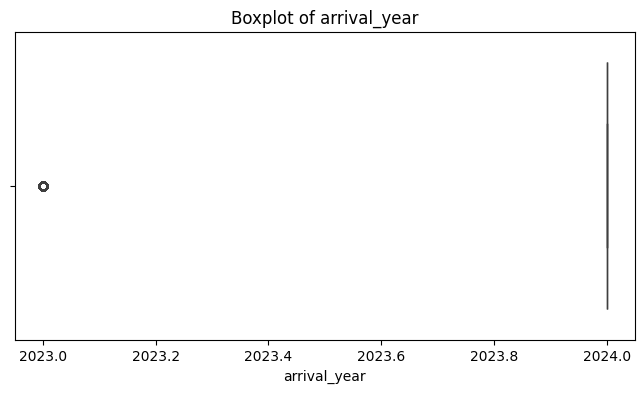

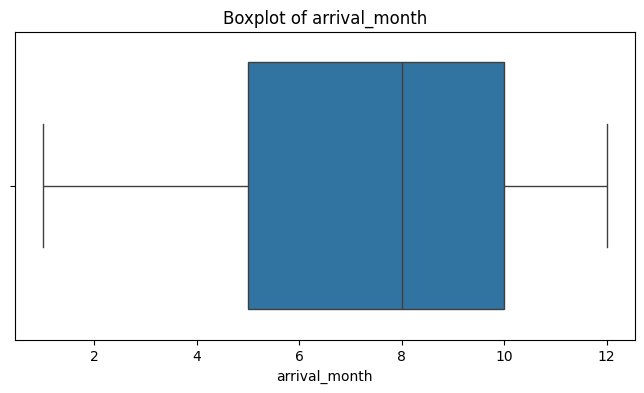

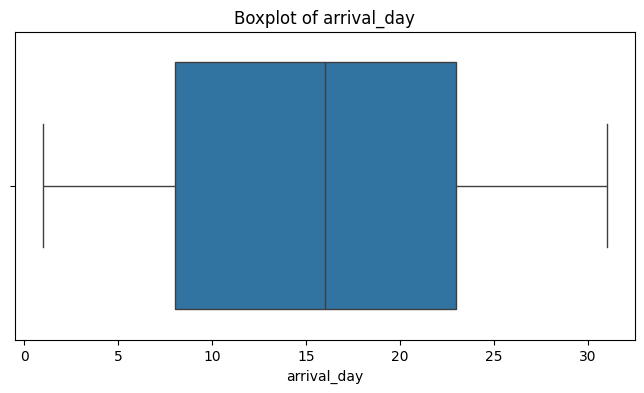

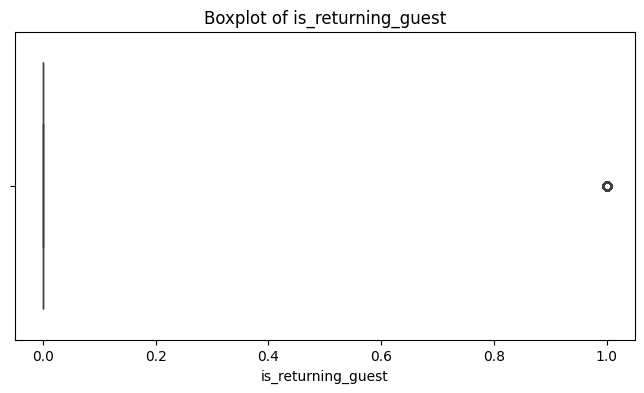

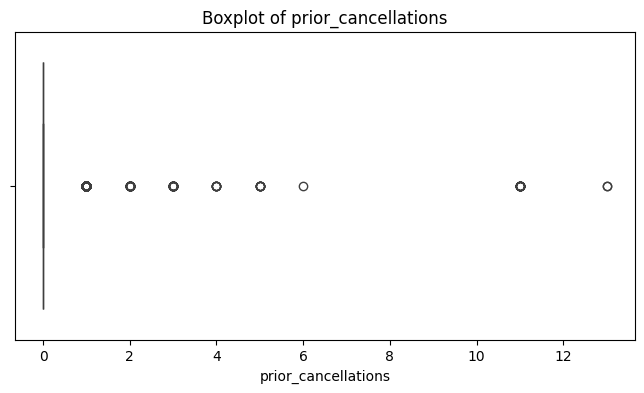

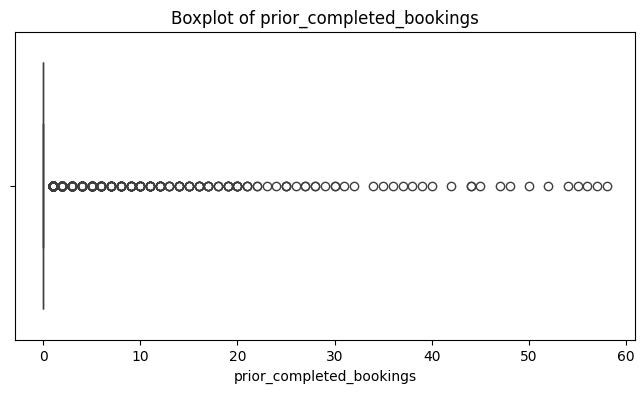

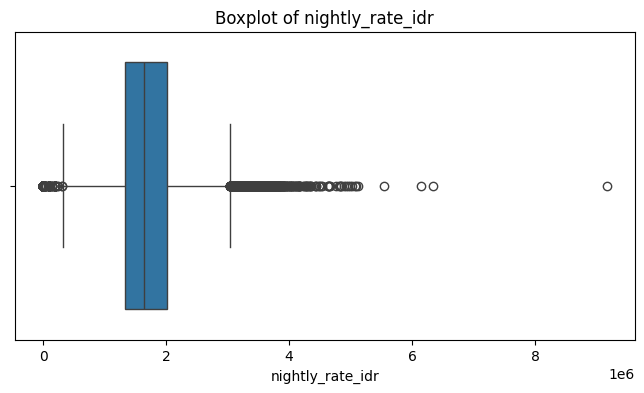

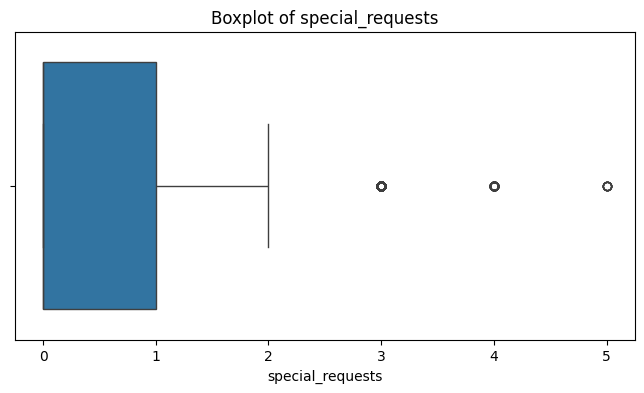

In [11]:
# Outlier 
for feature in numeric_features:
    plt.figure(figsize=(8, 4))
    sns.boxplot(x=train_df[feature])
    plt.title(f'Boxplot of {feature}')
    plt.xlabel(feature)
    plt.show()

#### Insight
- Outlier terbanyak ada pada nightly_rate_idr dan days_before_arrival. Nilainya masih wajar sehingga tidak dihapus.
- Pada fitur diskret seperti num_adults dan num_children, banyak nilai ditandai outlier hanya karena datanya didominasi satu nilai, bukan karena salah.

### 6. Fitur kategorikal

In [12]:
categorical_features = train_df.select_dtypes(include=['object']).columns.tolist()
categorical_features = [col for col in categorical_features if col not in unused_features]
print(f"Categorical features: {categorical_features}")

Categorical features: ['meal_package', 'room_category', 'booking_channel']


In [13]:
#Hitung jumlah nilai dan cancel rate per kategori untuk fitur kategorikal
for feature in categorical_features:
    value_counts = train_df[feature].value_counts()
    cancel_rate = train_df.groupby(feature)['is_canceled'].mean()
    print(f"\nFeature: {feature}")
    print("Value Counts:")
    print(value_counts)
    print("Cancel Rate:")
    print(cancel_rate)


Feature: meal_package
Value Counts:
meal_package
Breakfast     19654
Room Only      3713
Half Board     2242
Full Board        4
Name: count, dtype: int64
Cancel Rate:
meal_package
Breakfast     0.311438
Full Board    0.250000
Half Board    0.459411
Room Only     0.338002
Name: is_canceled, dtype: float64

Feature: room_category
Value Counts:
room_category
Type B    20447
Type G     4396
Type A      699
Type D      514
Type C      189
Type F      119
Type E        7
Name: count, dtype: int64
Cancel Rate:
room_category
Type A    0.426323
Type B    0.321416
Type C    0.248677
Type D    0.328794
Type E    0.285714
Type F    0.243697
Type G    0.341902
Name: is_canceled, dtype: float64

Feature: booking_channel
Value Counts:
booking_channel
Online Travel Agent    17511
Offline Agent           7960
Corporate               1513
Complimentary            301
Airline                   88
Name: count, dtype: int64
Cancel Rate:
booking_channel
Airline                0.306818
Complimentary       

In [14]:
for feature in categorical_features:
    rare_categories = train_df[feature].value_counts()[train_df[feature].value_counts() < 10].index.tolist()
    if rare_categories:
        print(f"\nFeature: {feature} has rare categories: {rare_categories}")



Feature: meal_package has rare categories: ['Full Board']

Feature: room_category has rare categories: ['Type E']


In [15]:
for feature in categorical_features:
    train_categories = set(train_df[feature].unique())
    test_categories = set(test_df[feature].unique())
    unseen_categories = test_categories - train_categories
    if unseen_categories:
        print(f"\nFeature: {feature} has unseen categories in test data: {unseen_categories}")

#### Insight
- booking_channel paling membedakan pembatalan. Online Travel Agent paling sering batal (36%), Corporate jarang (12%), dan Complimentary tidak pernah batal.
- Pada meal_package, Half Board paling sering batal (46%). Pada room_category, Type A paling sering batal (43%).
- Full Board dan Type E muncul kurang dari 10 kali, jadi cancel rate-nya belum bisa dipercaya.

### 7. Hubungan antarfitur

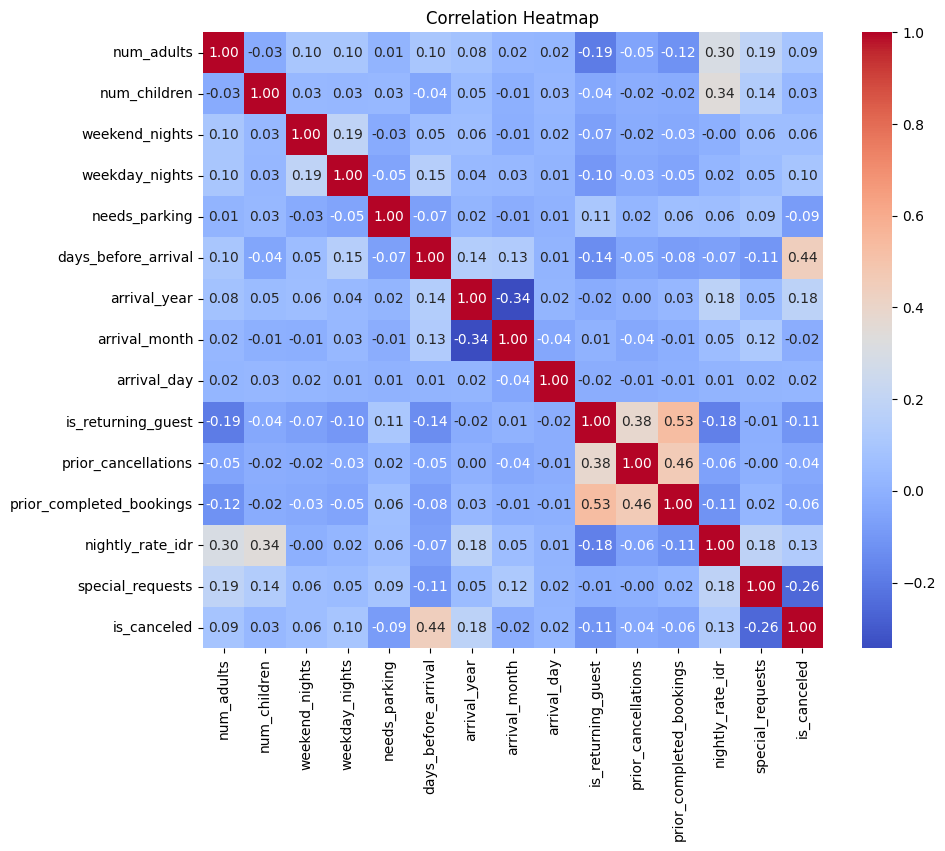

In [16]:
#Heatmap korelasi untuk fitur numerik dan target
numeric_features_with_target = numeric_features + ['is_canceled']
plt.figure(figsize=(10, 8))
sns.heatmap(train_df[numeric_features_with_target].corr(), annot=True, fmt=".2f", cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

#### Insight
- days_before_arrival paling berhubungan dengan pembatalan (0,44). Makin jauh hari booking dibuat, makin besar peluangnya dibatalkan.
- special_requests berhubungan terbalik (−0,26). Tamu yang punya permintaan khusus lebih jarang membatalkan.

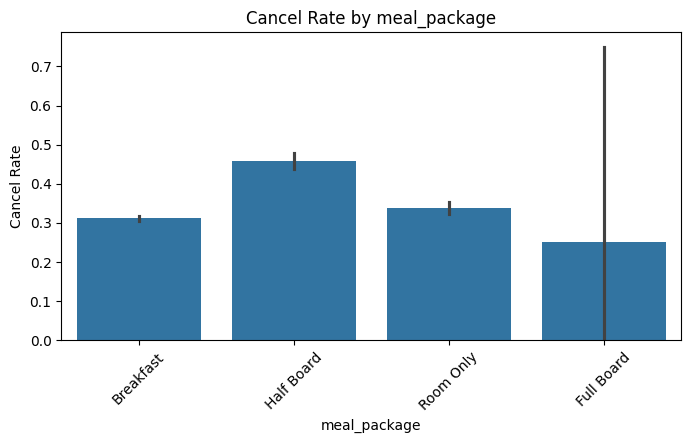

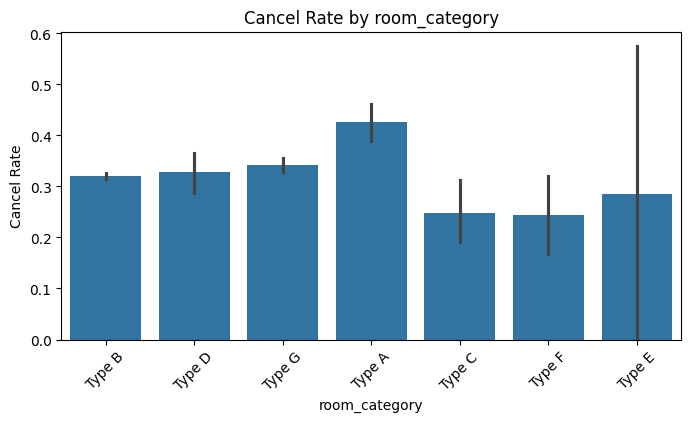

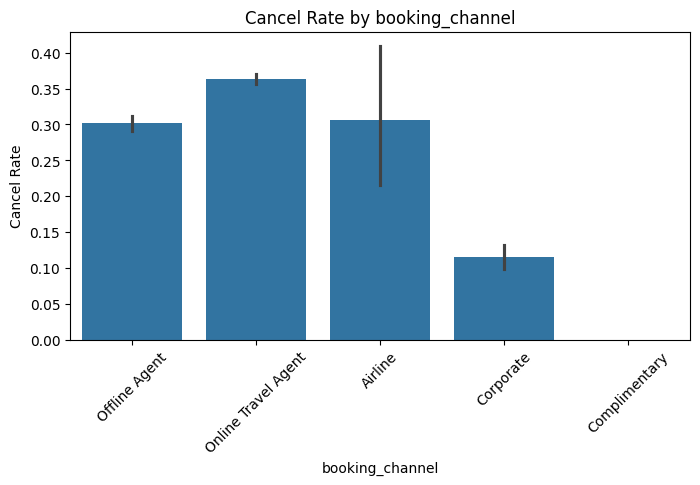

In [17]:
# Hubungan antara fitur kategorikal dan target
for feature in categorical_features:
    plt.figure(figsize=(8, 4))
    sns.barplot(x=feature, y='is_canceled', data=train_df)
    plt.title(f'Cancel Rate by {feature}')
    plt.xlabel(feature)
    plt.ylabel('Cancel Rate')
    plt.xticks(rotation=45)
    plt.show()

#### Insight
- Grafik menunjukkan hal yang sama dengan tabel sebelumnya. Perbedaan paling besar ada pada booking_channel, sedangkan perbedaan antar-room_category lebih kecil.

In [18]:
#Hubungan pake chi-square test untuk fitur kategorikal dan target
categorical_features_with_target = categorical_features + ['is_canceled']
for feature in categorical_features:
    contingency_table = pd.crosstab(train_df[feature], train_df['is_canceled'])
    chi2_stat, p_value, dof, expected = chi2_contingency(contingency_table)
    print(f"\nChi-square test for feature: {feature}")
    print(f"Chi-square Statistic: {chi2_stat:.4f}, p-value: {p_value:.4f}, Degrees of Freedom: {dof}")
    


Chi-square test for feature: meal_package
Chi-square Statistic: 201.8292, p-value: 0.0000, Degrees of Freedom: 3

Chi-square test for feature: room_category
Chi-square Statistic: 47.7565, p-value: 0.0000, Degrees of Freedom: 6

Chi-square test for feature: booking_channel
Chi-square Statistic: 585.1653, p-value: 0.0000, Degrees of Freedom: 4


#### Insight
- Ketiga fitur kategorikal berhubungan dengan pembatalan (p-value < 0,0001) sehingga layak dipakai. Hubungan terkuat ada pada booking_channel.

In [19]:
# periksa multikoliniaritas untuk fitur numerik dengan np.diag(np.linalg.pinv(corr))
corr = train_df[numeric_features].corr()
vif = np.diag(np.linalg.pinv(corr))
print("\nVariance Inflation Factor (VIF) for Numeric Features:")
for i, feature in enumerate(numeric_features):
    print(f"{feature}: {vif[i]:.2f}")


Variance Inflation Factor (VIF) for Numeric Features:
num_adults: 1.21
num_children: 1.17
weekend_nights: 1.05
weekday_nights: 1.07
needs_parking: 1.03
days_before_arrival: 1.16
arrival_year: 1.27
arrival_month: 1.24
arrival_day: 1.00
is_returning_guest: 1.54
prior_cancellations: 1.32
prior_completed_bookings: 1.58
nightly_rate_idr: 1.39
special_requests: 1.12


#### Insight
- Semua nilai VIF di bawah 1,6, jauh dari batas umum 5. Tidak ada fitur numerik yang saling tumpang tindih, jadi semuanya bisa dipakai.

### 8. Pola waktu

In [20]:
# cancel rate per arrival year dan month
for year in train_df['arrival_year'].unique():
    for month in train_df['arrival_month'].unique():
        subset = train_df[(train_df['arrival_year'] == year) & (train_df['arrival_month'] == month)]
        if not subset.empty:
            cancel_rate = subset['is_canceled'].mean()
            print(f"Cancel rate for {year}-{month}: {cancel_rate:.2f}")

Cancel rate for 2024-4: 0.36
Cancel rate for 2024-8: 0.46
Cancel rate for 2024-9: 0.47
Cancel rate for 2024-6: 0.41
Cancel rate for 2024-11: 0.34
Cancel rate for 2024-12: 0.17
Cancel rate for 2024-2: 0.26
Cancel rate for 2024-5: 0.37
Cancel rate for 2024-7: 0.42
Cancel rate for 2024-10: 0.47
Cancel rate for 2024-3: 0.30
Cancel rate for 2024-1: 0.03
Cancel rate for 2023-8: 0.19
Cancel rate for 2023-9: 0.11
Cancel rate for 2023-11: 0.04
Cancel rate for 2023-12: 0.03
Cancel rate for 2023-7: 0.64
Cancel rate for 2023-10: 0.16


#### Insight
- Pembatalan berubah mengikuti bulan. Pada 2024, cancel rate rendah di awal dan akhir tahun (3% pada Januari, 17% pada Desember), tetapi tinggi pada Agustus–Oktober (sekitar 47%).
- Data 2023 hanya mencakup Juli–Desember sehingga tidak bisa dibandingkan langsung dengan 2024.

## Decision Tree Learning (C4.5)
C4.5 dibangun dari nol di src/models/c45/c45.py. Pohon dibentuk dari atas ke bawah. Pada setiap node, model memilih atribut dengan gain ratio terbesar, yaitu information gain dibagi split information. Pembagian ini mencegah atribut dengan banyak kategori selalu terpilih hanya karena cabangnya banyak. Atribut kategorikal dipecah menjadi satu cabang untuk setiap kategori, sedangkan atribut numerik dipecah menjadi dua cabang dengan threshold di titik tengah dua nilai yang berurutan.

Nilai kosong tidak perlu diimputasi. Saat training, data yang nilainya kosong ikut ke semua cabang dengan bobot sebesar proporsi data di cabang tersebut. Saat prediksi, hasil dari semua cabang digabung dengan bobot yang sama. Setelah pohon selesai dibangun, Reduced Error Pruning memangkas subtree selama pemangkasan itu menurunkan error pada data pruning.

Split validation sama dengan Naive Bayes (seed 42, 5 fold, baris identik dikelompokkan). Training split dibagi lagi menjadi data grow (80%) untuk membangun pohon dan data pruning (20%) untuk pemangkasan, sehingga validation tidak dipakai sampai tahap evaluasi. Metrik utama yang dipakai adalah F1 macro, sama dengan metrik leaderboard Kaggle.

### Preprocessing dan feature engineering
C4.5 tidak membutuhkan scaling, imputasi, maupun encoding. Preprocessing di sini hanya merapikan nilai yang janggal dan menambah fitur turunan dari temuan EDA.
- Tarif 0 di luar kanal Complimentary dianggap nilai kosong karena tidak wajar.
- Jumlah anak dibatasi maksimal 4 karena nilai di atasnya hanya muncul pada 3 baris.
- Kategori yang muncul kurang dari 10 kali di training digabung menjadi Other agar pohon tidak membuat cabang dari beberapa sampel saja.
- Fitur baru terdiri atas penanda special_requests kosong, total malam, total tamu, indeks bulan kedatangan (menangkap tren 2023 dan 2024), hari kedatangan dalam seminggu, dan tarif per orang.

Kategori langka dicari hanya dari training split, lalu dipakai juga untuk validation dan test.

In [21]:
import copy
from models.c45 import C45DecisionTree
from models.c45.visualization import plot_tree as c45_plot_tree

# Split sama persis dengan Naive Bayes (seed, 5 fold, grup baris identik)
dtl_X_raw = train_df.drop(columns=['is_canceled', 'id'])
dtl_y_raw = train_df['is_canceled']
dtl_groups = pd.util.hash_pandas_object(dtl_X_raw, index=False)
dtl_splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
dtl_train_idx, dtl_valid_idx = next(dtl_splitter.split(dtl_X_raw, dtl_y_raw, dtl_groups))
assert set(dtl_groups.iloc[dtl_train_idx]).isdisjoint(dtl_groups.iloc[dtl_valid_idx])
dtl_text_features = ['meal_package', 'room_category', 'booking_channel']


def dtl_fit_rare(raw):
    # kategori dengan kurang dari 10 baris, dipelajari dari data training saja
    return {col: raw[col].value_counts()[lambda counts: counts < 10].index.tolist() for col in dtl_text_features}


def dtl_preprocess(raw, rare):
    df = raw.copy()
    df[dtl_text_features] = df[dtl_text_features].astype(object)  # C4.5 mengenali kategorikal dari dtype object
    invalid_rate = (df['nightly_rate_idr'] == 0) & (df['booking_channel'] != 'Complimentary')
    df.loc[invalid_rate, 'nightly_rate_idr'] = np.nan
    df['num_children'] = df['num_children'].clip(upper=4)
    for col, categories in rare.items():
        df.loc[df[col].isin(categories), col] = 'Other'

    df['special_requests_missing'] = df['special_requests'].isna().astype(int)
    df['total_nights'] = df['weekend_nights'] + df['weekday_nights']
    df['total_guests'] = df['num_adults'] + df['num_children']
    df['month_index'] = (df['arrival_year'] - 2023) * 12 + df['arrival_month']
    arrival_date = pd.to_datetime(
        dict(year=df['arrival_year'], month=df['arrival_month'], day=df['arrival_day']), errors='coerce'
    )
    df['arrival_dayofweek'] = arrival_date.dt.dayofweek
    df['rate_per_person'] = df['nightly_rate_idr'] / df['total_guests'].replace(0, np.nan)
    return df


def dtl_grow_prune_split(X, y, groups, index):
    # index dibagi lagi menjadi grow (80%) dan prune (20%), baris identik tetap satu kelompok
    grow_rel, prune_rel = next(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED).split(
        X.iloc[index], y.iloc[index], groups.iloc[index]
    ))
    return index[grow_rel], index[prune_rel]


dtl_rare = dtl_fit_rare(dtl_X_raw.iloc[dtl_train_idx])
dtl_X = dtl_preprocess(dtl_X_raw, dtl_rare)
dtl_categorical = dtl_X.select_dtypes(include='object').columns.tolist()
dtl_grow_idx, dtl_prune_idx = dtl_grow_prune_split(dtl_X, dtl_y_raw, dtl_groups, dtl_train_idx)
dtl_X_grow, dtl_y_grow = dtl_X.iloc[dtl_grow_idx], dtl_y_raw.iloc[dtl_grow_idx]
dtl_X_prune, dtl_y_prune = dtl_X.iloc[dtl_prune_idx], dtl_y_raw.iloc[dtl_prune_idx]
dtl_X_valid, dtl_y_valid = dtl_X.iloc[dtl_valid_idx], dtl_y_raw.iloc[dtl_valid_idx]
print(f'Grow: {len(dtl_grow_idx)}, prune: {len(dtl_prune_idx)}, validation: {len(dtl_valid_idx)}')
print('Kategori langka:', dtl_rare)
print(f'Jumlah fitur: {dtl_X.shape[1]} (kategorikal: {dtl_categorical})')

Grow: 17520, prune: 4379, validation: 5474
Kategori langka: {'meal_package': ['Full Board'], 'room_category': ['Type E'], 'booking_channel': []}
Jumlah fitur: 23 (kategorikal: ['meal_package', 'room_category', 'booking_channel'])


### Pemilihan faktor oversampling
Data training hanya berisi sekitar 33% booking batal, sehingga pohon cenderung jarang menebak batal dan recall-nya rendah. Random oversampling menggandakan baris kelas batal secara acak sampai jumlahnya menjadi beberapa kali lipat. Oversampling hanya diterapkan pada data grow, sedangkan data pruning, validation, dan test tetap memakai distribusi asli.

Faktor oversampling dipilih dengan 5-fold CV di dalam training split saja, sehingga validation tetap tidak tersentuh. Setiap fold menjalankan langkah yang sama dengan model akhir, yaitu split grow dan prune, oversampling, training, lalu pruning. Sel ini menjalankan 15 kali training sehingga butuh beberapa menit.

Referensi oversampling adalah N. Japkowicz dan S. Stephen, "The class imbalance problem: A systematic study," Intelligent Data Analysis, 6(5), 2002.

In [22]:
def dtl_oversample(index, y, factor):
    # baris kelas batal digandakan acak sampai jumlahnya factor kali lipat
    positive = index[y.iloc[index].to_numpy() == 1]
    rng = np.random.default_rng(SEED)
    extra = rng.choice(positive, int(round((factor - 1) * len(positive))))
    return np.concatenate([index, extra])


def dtl_train(X, y, groups, index, factor):
    grow, prune = dtl_grow_prune_split(X, y, groups, index)
    grow = dtl_oversample(grow, y, factor)
    return C45DecisionTree().fit(X.iloc[grow], y.iloc[grow]).prune(X.iloc[prune], y.iloc[prune])


DTL_FACTORS = [1.0, 1.5, 2.0]
dtl_cv_folds = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED).split(
    dtl_X.iloc[dtl_train_idx], dtl_y_raw.iloc[dtl_train_idx], dtl_groups.iloc[dtl_train_idx]
))
dtl_cv_rows = []
for dtl_factor in DTL_FACTORS:
    dtl_scores = []
    for dtl_fold_train, dtl_fold_val in dtl_cv_folds:
        dtl_fold_model = dtl_train(dtl_X, dtl_y_raw, dtl_groups, dtl_train_idx[dtl_fold_train], dtl_factor)
        dtl_fold_val_idx = dtl_train_idx[dtl_fold_val]
        dtl_scores.append(f1_score(dtl_y_raw.iloc[dtl_fold_val_idx],
                                   dtl_fold_model.predict(dtl_X.iloc[dtl_fold_val_idx]), average='macro'))
    dtl_cv_rows.append({'factor': dtl_factor, 'cv_f1_macro': np.mean(dtl_scores), 'cv_std': np.std(dtl_scores)})
dtl_cv_results = pd.DataFrame(dtl_cv_rows)
DTL_FACTOR = float(dtl_cv_results.loc[dtl_cv_results['cv_f1_macro'].idxmax(), 'factor'])
print('Faktor oversampling terpilih:', DTL_FACTOR)
dtl_cv_results

Faktor oversampling terpilih: 2.0


,factor,cv_f1_macro,cv_std
0,1.0,0.827125,0.009824
1,1.5,0.825556,0.012780
2,2.0,0.828666,0.010487


Hasil ketiga faktor sangat mirip. F1 macro berkisar 0,826–0,829, sedangkan variasi antar-fold sekitar 0,01. Faktor 2,0 terpilih karena rata-ratanya paling tinggi, sama dengan hasil CV pada eksperimen sebelumnya, tetapi keunggulannya terlalu kecil untuk dianggap nyata.

### Training dan pruning
Pohon dibangun tanpa batas kedalaman sampai setiap leaf murni atau atribut tidak dapat memecah data lagi, lalu dipangkas dengan data pruning. Tabel membandingkan tiga tahap, yaitu pohon tanpa pruning, pohon dengan pruning, dan pohon dengan pruning serta oversampling. Model tidak memiliki predict_proba, jadi skor ROC AUC diambil dari proporsi kelas batal di leaf yang dicapai.

In [23]:
def dtl_predict_proba(model, X):
    # proporsi kelas di leaf (digabung dengan bobot p_i jika ada nilai kosong)
    rows = X[model.feature_names].to_numpy(dtype=object)
    return np.array([model.predict_distribution(model.root, row) for row in rows])


def dtl_evaluate(model, X, y):
    predictions = model.predict(X)
    proba_cancel = dtl_predict_proba(model, X)[:, 1]
    return {
        'n_node': model.count_nodes(),
        'accuracy': accuracy_score(y, predictions),
        'precision': precision_score(y, predictions, zero_division=0),
        'recall': recall_score(y, predictions, zero_division=0),
        'f1': f1_score(y, predictions, zero_division=0),
        'f1_macro': f1_score(y, predictions, average='macro'),
        'roc_auc': roc_auc_score(y, proba_cancel),
    }


dtl_start = time.perf_counter()
dtl_plain = C45DecisionTree().fit(dtl_X_grow, dtl_y_grow)
dtl_plain_seconds = time.perf_counter() - dtl_start
dtl_unpruned = copy.deepcopy(dtl_plain)
dtl_plain.prune(dtl_X_prune, dtl_y_prune)

dtl_start = time.perf_counter()
dtl_tree = dtl_train(dtl_X, dtl_y_raw, dtl_groups, dtl_train_idx, DTL_FACTOR)
dtl_tree_seconds = time.perf_counter() - dtl_start

dtl_results = pd.DataFrame([
    {'model': 'C4.5 tanpa pruning', 'seconds': dtl_plain_seconds, **dtl_evaluate(dtl_unpruned, dtl_X_valid, dtl_y_valid)},
    {'model': 'C4.5 + Reduced Error Pruning', 'seconds': dtl_plain_seconds,
     **dtl_evaluate(dtl_plain, dtl_X_valid, dtl_y_valid)},
    {'model': f'C4.5 + REP + oversampling x{DTL_FACTOR}', 'seconds': dtl_tree_seconds,
     **dtl_evaluate(dtl_tree, dtl_X_valid, dtl_y_valid)},
])
dtl_results

,model,seconds,n_node,accuracy,precision,recall,f1,f1_macro,roc_auc
0,C4.5 tanpa pruning,97.468869,57264,0.822981,0.720500,0.744382,0.732246,0.800016,0.827550
1,C4.5 + Reduced Error Pruning,97.468869,9764,0.867008,0.818788,0.758989,0.787755,0.845460,0.887426
2,C4.5 + REP + oversampling x2.0,94.676038,7566,0.859335,0.785957,0.779775,0.782854,0.839414,0.873091


Fitur turunan menambah banyak kandidat threshold, sehingga pohon tanpa pruning membengkak menjadi 57.264 node dengan F1 macro hanya 0,800. Reduced Error Pruning memangkasnya menjadi 9.764 node dan menaikkan F1 macro menjadi 0,845. Sebelum preprocessing dan feature engineering ditambahkan, pohon dengan pruning hanya mencapai F1 kelas batal 0,769, sedangkan sekarang 0,788.

Oversampling ×2 menaikkan recall dari 0,759 menjadi 0,780, tetapi precision turun dari 0,819 menjadi 0,786. Akibatnya, F1 macro pada validation justru sedikit turun dari 0,845 menjadi 0,839. Selisih ini masih dalam rentang variasi antar-fold, jadi oversampling tidak terbukti membantu maupun merugikan pada split ini. Oversampling tetap dipakai untuk model final karena faktornya dipilih lewat CV, bukan dari validation. Training satu pohon kini butuh sekitar 80 detik karena fitur kontinu seperti rate_per_person memiliki banyak nilai unik.

### Visualisasi pohon
Pohon akhir masih terlalu besar untuk digambar seluruhnya. Grafik hanya menampilkan tiga level teratas dan tiga cabang dengan proporsi data terbesar di setiap node. Angka p pada cabang adalah proporsi data training yang masuk ke cabang tersebut, sedangkan persentase pada leaf adalah keyakinan prediksi di leaf itu.

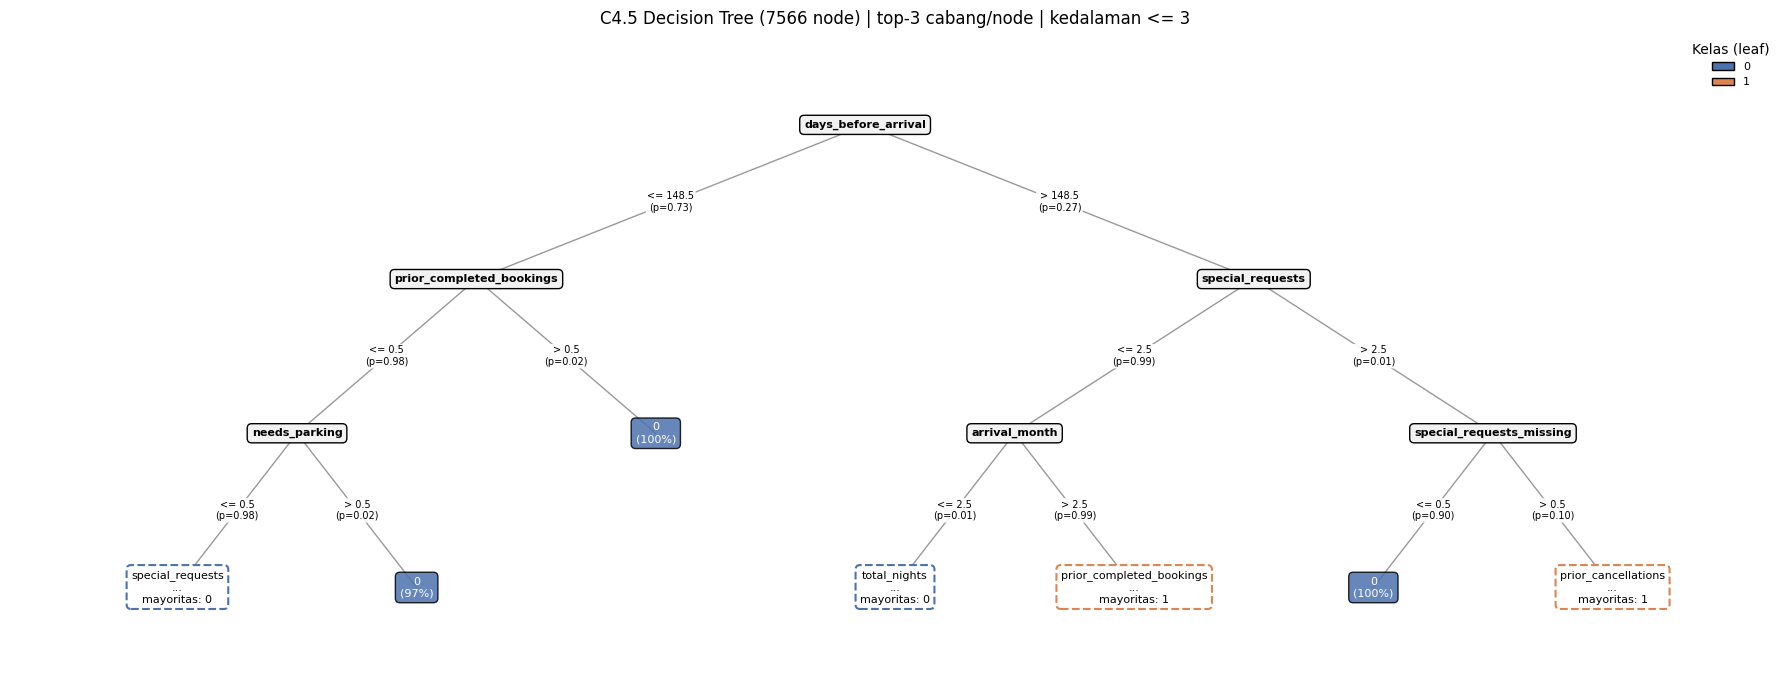

In [24]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
dtl_fig, dtl_ax = c45_plot_tree(
    dtl_tree, top_n=3, max_depth=3, path=OUTPUT_DIR / 'c45_tree.png', figsize=(18, 7)
)
plt.show()

Atribut pertama tetap days_before_arrival dengan threshold 148,5 hari, sesuai temuan EDA bahwa lead time paling berhubungan dengan pembatalan. Pada booking dengan lead time panjang, pohon memeriksa special_requests, lalu bulan kedatangan, dan cabang dengan sedikit permintaan khusus cenderung berakhir pada mayoritas batal. Fitur turunan special_requests_missing juga muncul di level atas, yang menunjukkan bahwa kosongnya kolom special_requests ikut membawa informasi. Pada lead time pendek, tamu yang pernah menyelesaikan booking sebelumnya atau membutuhkan parkir hampir tidak pernah membatalkan. Proporsi p pada grafik dihitung dari data grow yang sudah di-oversample, sehingga porsi cabang batal terlihat lebih besar daripada di data asli.

### Perbandingan dengan scikit-learn
DecisionTreeClassifier dengan criterion entropy adalah pembanding terdekat, tetapi algoritmanya berbeda. scikit-learn memakai CART, yaitu selalu memecah menjadi dua cabang dengan information gain, bukan gain ratio. scikit-learn juga tidak menerima NaN dan teks, jadi nilai kosong diisi dulu (median untuk numerik dan modus untuk kategorikal) dan kategori dikodekan menjadi angka. Agar setara, scikit-learn memakai fitur, data grow hasil oversampling, dan data pruning yang sama. Data pruning dipakai untuk memilih ccp_alpha.

In [25]:
dtl_numeric = [c for c in dtl_X.columns if c not in dtl_categorical]
dtl_sk_preprocessor = ColumnTransformer([
    ('numeric', SimpleImputer(strategy='median'), dtl_numeric),
    ('categorical', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)),
    ]), dtl_categorical),
])
dtl_sk_grow_idx = dtl_oversample(dtl_grow_idx, dtl_y_raw, DTL_FACTOR)
dtl_sk_grow = dtl_sk_preprocessor.fit_transform(dtl_X.iloc[dtl_sk_grow_idx])
dtl_sk_y_grow = dtl_y_raw.iloc[dtl_sk_grow_idx]
dtl_sk_prune = dtl_sk_preprocessor.transform(dtl_X_prune)
dtl_sk_valid = dtl_sk_preprocessor.transform(dtl_X_valid)

# ccp_alpha dipilih dari F1 macro pada data pruning, bukan validation
dtl_sk_alphas = [0.0, 0.0001, 0.0002, 0.0005, 0.001, 0.002]
dtl_sk_models = {
    alpha: DecisionTreeClassifier(criterion='entropy', ccp_alpha=alpha, random_state=SEED).fit(dtl_sk_grow, dtl_sk_y_grow)
    for alpha in dtl_sk_alphas
}
dtl_sk_best_alpha = max(
    dtl_sk_alphas, key=lambda a: f1_score(dtl_y_prune, dtl_sk_models[a].predict(dtl_sk_prune), average='macro')
)
print('ccp_alpha terpilih:', dtl_sk_best_alpha)


def dtl_evaluate_sklearn(model):
    predictions = model.predict(dtl_sk_valid)
    return {
        'n_node': model.tree_.node_count,
        'accuracy': accuracy_score(dtl_y_valid, predictions),
        'precision': precision_score(dtl_y_valid, predictions, zero_division=0),
        'recall': recall_score(dtl_y_valid, predictions, zero_division=0),
        'f1': f1_score(dtl_y_valid, predictions, zero_division=0),
        'f1_macro': f1_score(dtl_y_valid, predictions, average='macro'),
        'roc_auc': roc_auc_score(dtl_y_valid, model.predict_proba(dtl_sk_valid)[:, 1]),
    }


dtl_comparison = pd.DataFrame([
    {'model': f'C4.5 + REP + oversampling x{DTL_FACTOR}', **dtl_evaluate(dtl_tree, dtl_X_valid, dtl_y_valid)},
    {'model': 'scikit-learn tanpa pruning', **dtl_evaluate_sklearn(dtl_sk_models[0.0])},
    {'model': f'scikit-learn ccp_alpha={dtl_sk_best_alpha}', **dtl_evaluate_sklearn(dtl_sk_models[dtl_sk_best_alpha])},
])
dtl_comparison

ccp_alpha terpilih: 0.0005


,model,n_node,accuracy,precision,recall,f1,f1_macro,roc_auc
0,C4.5 + REP + oversampling x2.0,7566,0.859335,0.785957,0.779775,0.782854,0.839414,0.873091
1,scikit-learn tanpa pruning,4319,0.828462,0.725711,0.759551,0.742245,0.806852,0.810609
2,scikit-learn ccp_alpha=0.0005,389,0.839971,0.714421,0.846067,0.774691,0.825306,0.916863


Dengan fitur dan data yang sama, C4.5 unggul pada F1 macro (0,839) dibandingkan scikit-learn tanpa pruning (0,807) maupun dengan ccp_alpha 0,0005 (0,825). scikit-learn dengan pruning memiliki recall lebih tinggi (0,846) dan ROC AUC lebih tinggi (0,917) dengan pohon yang jauh lebih kecil (389 node), tetapi precision-nya lebih rendah. Perbedaan ini berasal dari algoritma yang berbeda, yaitu gain ratio dengan cabang per kategori pada C4.5 dan pemecahan biner dengan cost-complexity pruning pada CART. ROC AUC C4.5 yang lebih rendah kemungkinan dipengaruhi oleh banyaknya leaf murni, sehingga skor probabilitasnya kurang halus untuk mengurutkan data.

### Model final untuk submisi
Model pada tabel di atas hanya dibangun dari 64% data. Untuk submisi, langkah yang sama diulang pada seluruh train.csv. Kategori langka dicari ulang dari seluruh data, lalu data dibagi menjadi grow (80%) dan pruning (20%), kelas batal pada data grow di-oversample dengan faktor terpilih, dan pohon dipangkas dengan data pruning. Model ini tidak bisa dievaluasi pada validation karena validation ikut dipakai untuk training, sehingga skor validation di atas tetap menjadi acuan performanya.

In [26]:
dtl_final_rare = dtl_fit_rare(dtl_X_raw)
dtl_final_X = dtl_preprocess(dtl_X_raw, dtl_final_rare)
dtl_start = time.perf_counter()
dtl_final_model = dtl_train(dtl_final_X, dtl_y_raw, dtl_groups, np.arange(len(dtl_final_X)), DTL_FACTOR)
print(f'Training selesai dalam {time.perf_counter() - dtl_start:.1f} detik, jumlah node: {dtl_final_model.count_nodes()}')

Training selesai dalam 140.1 detik, jumlah node: 5651


### Simpan dan muat model
Model final disimpan dengan pickle bersama daftar kategori langka, karena keduanya dibutuhkan untuk memproses data mentah dengan cara yang sama saat prediksi. Hanya muat berkas pickle dari sumber tepercaya karena pemuatan dapat menjalankan kode.

In [27]:
dtl_model_path = OUTPUT_DIR / 'c45_final.pkl'
dtl_rare_path = OUTPUT_DIR / 'c45_rare_categories.pkl'
dtl_final_model.save(dtl_model_path)
with dtl_rare_path.open('wb') as dtl_file:
    pickle.dump(dtl_final_rare, dtl_file)

dtl_loaded = C45DecisionTree.load(dtl_model_path)
with dtl_rare_path.open('rb') as dtl_file:
    dtl_loaded_rare = pickle.load(dtl_file)

dtl_demo_raw = test_df.drop(columns=['id']).iloc[:5]
dtl_demo_before = dtl_predict_proba(dtl_final_model, dtl_preprocess(dtl_demo_raw, dtl_final_rare))
dtl_demo_after = dtl_predict_proba(dtl_loaded, dtl_preprocess(dtl_demo_raw, dtl_loaded_rare))
np.testing.assert_allclose(dtl_demo_before, dtl_demo_after)
pd.DataFrame({
    'id': test_df['id'].iloc[:5].to_numpy(),
    'P(batal) awal': dtl_demo_before[:, 1].round(4),
    'P(batal) muat ulang': dtl_demo_after[:, 1].round(4),
})

,id,P(batal) awal,P(batal) muat ulang
0,5cb6f473,0.0000,0.0000
1,c06b4ab3,0.9625,0.9625
2,22bf3fc3,0.2276,0.2276
3,25408a48,0.0000,0.0000
4,621586b6,0.2276,0.2276


## Persiapan Data dan Baseline SVM
SVM memakai fitur numerik dan kategorikal yang diproses tanpa melihat validation set. Baris dengan fitur sama dikelompokkan agar salinan identik tidak bocor ke validation. Training dibatasi 1000 baris terstratifikasi untuk semua metode. Kernel padat membutuhkan memori kuadratik; matriks kernel seluruh 27.373 baris saja sekitar 6 GB. Hasil subset bukan hasil training seluruh data.

In [28]:
SVM_TRAIN_LIMIT = 1000  # None memakai seluruh training split dan membutuhkan lebih banyak memori.
svm_X_raw = train_df.drop(columns=['is_canceled', 'id'])
svm_y_raw = train_df['is_canceled']
svm_groups = pd.util.hash_pandas_object(svm_X_raw, index=False)
svm_splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
svm_train_indices, svm_valid_indices = next(
    svm_splitter.split(svm_X_raw, svm_y_raw, svm_groups)
)
assert set(svm_groups.iloc[svm_train_indices]).isdisjoint(
    svm_groups.iloc[svm_valid_indices]
)
if SVM_TRAIN_LIMIT is not None and len(svm_train_indices) > SVM_TRAIN_LIMIT:
    svm_train_indices, _ = train_test_split(
        svm_train_indices, train_size=SVM_TRAIN_LIMIT,
        stratify=svm_y_raw.iloc[svm_train_indices], random_state=SEED,
    )
svm_numeric_features = svm_X_raw.select_dtypes(include='number').columns.tolist()
svm_categorical_features = [
    col for col in svm_X_raw.columns if col not in svm_numeric_features
]
svm_preprocessor = ColumnTransformer([
    ('numeric', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
    ]), svm_numeric_features),
    ('categorical', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
    ]), svm_categorical_features),
])
svm_X_train = svm_preprocessor.fit_transform(svm_X_raw.iloc[svm_train_indices])
svm_X_valid = svm_preprocessor.transform(svm_X_raw.iloc[svm_valid_indices])
svm_y_train = svm_y_raw.iloc[svm_train_indices]
svm_y_valid = svm_y_raw.iloc[svm_valid_indices]
print(f'Train: {svm_X_train.shape}; validation: {svm_X_valid.shape}')

Train: (1000, 29); validation: (5474, 29)


### Perbandingan baseline scikit-learn
Semua kernel memakai parameter bersama. Nilai gamma untuk kernel RBF dan polinomial ditetapkan dari jumlah fitur hasil preprocessing.

In [29]:
svm_kernel_configs = {
    'linear': {'kernel': 'linear'},
    'poly': {'kernel': 'poly'},
    'rbf': {'kernel': 'rbf'},
}
SVM_MAX_ITER = 50000
svm_shared_params = {
    'C': 1, 'degree': 3, 'gamma': 1 / svm_X_train.shape[1],
    'coef0': 1, 'tol': 1e-3,
}
svm_sklearn_params = {**svm_shared_params, 'max_iter': -1}
svm_sklearn_models = {
    name: SVC(**svm_sklearn_params, **config)
    for name, config in svm_kernel_configs.items()
}

def svm_evaluate_model(name, model, fit_seconds, backend, solver):
    scores = model.decision_function(svm_X_valid)
    predictions = model.predict(svm_X_valid)
    fit_status = int(model.fit_status_)
    return {
        'backend': backend, 'solver': solver, 'kernel': name,
        'accuracy': accuracy_score(svm_y_valid, predictions),
        'precision': precision_score(svm_y_valid, predictions, zero_division=0),
        'recall': recall_score(svm_y_valid, predictions, zero_division=0),
        'f1': f1_score(svm_y_valid, predictions, zero_division=0),
        'roc_auc': roc_auc_score(svm_y_valid, scores),
        'train_time': fit_seconds,
        'n_support': int(np.sum(model.n_support_)),
        'n_iter': int(np.asarray(model.n_iter_).sum()),
        'converged': bool(getattr(model, 'converged_', fit_status == 0)),
        'fit_status': fit_status,
    }

svm_sklearn_results = []
for svm_name, svm_model in svm_sklearn_models.items():
    svm_start = time.perf_counter()
    svm_model.fit(svm_X_train, svm_y_train)
    svm_fit_seconds = time.perf_counter() - svm_start
    svm_sklearn_results.append(svm_evaluate_model(
        svm_name, svm_model, svm_fit_seconds, 'sklearn', 'libsvm'
    ))
pd.DataFrame(svm_sklearn_results)

,backend,solver,kernel,accuracy,precision,recall,f1,roc_auc,train_time,n_support,n_iter,converged,fit_status
0,sklearn,libsvm,linear,0.805992,0.737748,0.625843,0.677204,0.851121,0.044624,499,7828,True,0
1,sklearn,libsvm,poly,0.799781,0.740169,0.592135,0.657928,0.856609,0.029886,514,1473,True,0
2,sklearn,libsvm,rbf,0.805809,0.773873,0.569101,0.655876,0.854488,0.034761,567,566,True,0


### SVM custom dan tabel gabungan
QP dan SMO memakai baris, preprocessing, serta parameter kernel yang sama dengan SVC. Batas custom adalah 50.000 iterasi, sedangkan SVC tidak dibatasi. Definisi iterasi setiap solver berbeda, sehingga jumlah iterasi bukan ukuran biaya yang setara. Status konvergensi dan waktu fit dilaporkan tanpa menyembunyikan kegagalan konvergensi.

In [30]:
svm_custom_models = {}
svm_custom_results = []
for svm_solver in ('qp', 'smo'):
    for svm_name, svm_config in svm_kernel_configs.items():
        svm_model = SVM(
            **svm_shared_params, **svm_config, solver=svm_solver,
            max_iter=SVM_MAX_ITER, random_state=SEED,
        )
        svm_start = time.perf_counter()
        svm_model.fit(svm_X_train, svm_y_train)
        svm_fit_seconds = time.perf_counter() - svm_start
        svm_custom_models[(svm_solver, svm_name)] = svm_model
        svm_custom_results.append(svm_evaluate_model(
            svm_name, svm_model, svm_fit_seconds, 'custom', svm_solver
        ))
        print(f'{svm_solver}/{svm_name}: {svm_fit_seconds:.2f}s, '
              f'n_iter={svm_model.n_iter_}, converged={svm_model.converged_}')
svm_results = pd.DataFrame(svm_sklearn_results + svm_custom_results)
svm_results.sort_values(['kernel', 'backend', 'solver']).reset_index(drop=True)

qp/linear: 5.65s, n_iter=4077, converged=True


qp/poly: 39.04s, n_iter=29524, converged=True


qp/rbf: 2.72s, n_iter=1877, converged=True


smo/linear: 3.13s, n_iter=3737, converged=True


smo/poly: 0.98s, n_iter=298, converged=True


smo/rbf: 0.64s, n_iter=103, converged=True


,backend,solver,kernel,accuracy,precision,recall,f1,roc_auc,train_time,n_support,n_iter,converged,fit_status
0,custom,qp,linear,0.805809,0.737575,0.625281,0.676801,0.851137,5.648951,498,4077,True,0
1,custom,smo,linear,0.805992,0.737748,0.625843,0.677204,0.851116,3.127074,503,3737,True,0
2,sklearn,libsvm,linear,0.805992,0.737748,0.625843,0.677204,0.851121,0.044624,499,7828,True,0
3,custom,qp,poly,0.799781,0.740169,0.592135,0.657928,0.856608,39.038524,514,29524,True,0
4,custom,smo,poly,0.799781,0.740169,0.592135,0.657928,0.856615,0.978770,515,298,True,0
5,sklearn,libsvm,poly,0.799781,0.740169,0.592135,0.657928,0.856609,0.029886,514,1473,True,0
6,custom,qp,rbf,0.805809,0.773873,0.569101,0.655876,0.854488,2.722337,567,1877,True,0
7,custom,smo,rbf,0.805809,0.773873,0.569101,0.655876,0.854492,0.644318,569,103,True,0
8,sklearn,libsvm,rbf,0.805809,0.773873,0.569101,0.655876,0.854488,0.034761,567,566,True,0


### Batas keputusan pada PCA dua dimensi
PCA hanya di-fit pada training. Enam model baru dilatih pada koordinat dua dimensi, dengan gamma = 1/2 untuk kedua solver. Grafik ini bukan proyeksi batas model berdimensi tinggi pada tabel evaluasi. Garis skor -1 dan +1 menunjukkan level margin, sedangkan skor 0 adalah batas keputusan; level tersebut bukan jarak Euclidean untuk kernel nonlinear. Lingkaran menandai support vector. Kontur di luar rentang skor diberi keterangan oleh helper. Waktu, iterasi, dan status model visualisasi ditampilkan terpisah.

PCA qp/linear: 0.64s, n_iter=323, converged=True


D:\proyek\IF3170_G14_LalapKaoBole\src\models\svm\svm.py:192: RuntimeWarning: SVM optimization stopped before convergence
  warnings.warn("SVM optimization stopped before convergence", RuntimeWarning)


PCA qp/poly: 67.31s, n_iter=50000, converged=False


PCA qp/rbf: 3.02s, n_iter=2146, converged=True


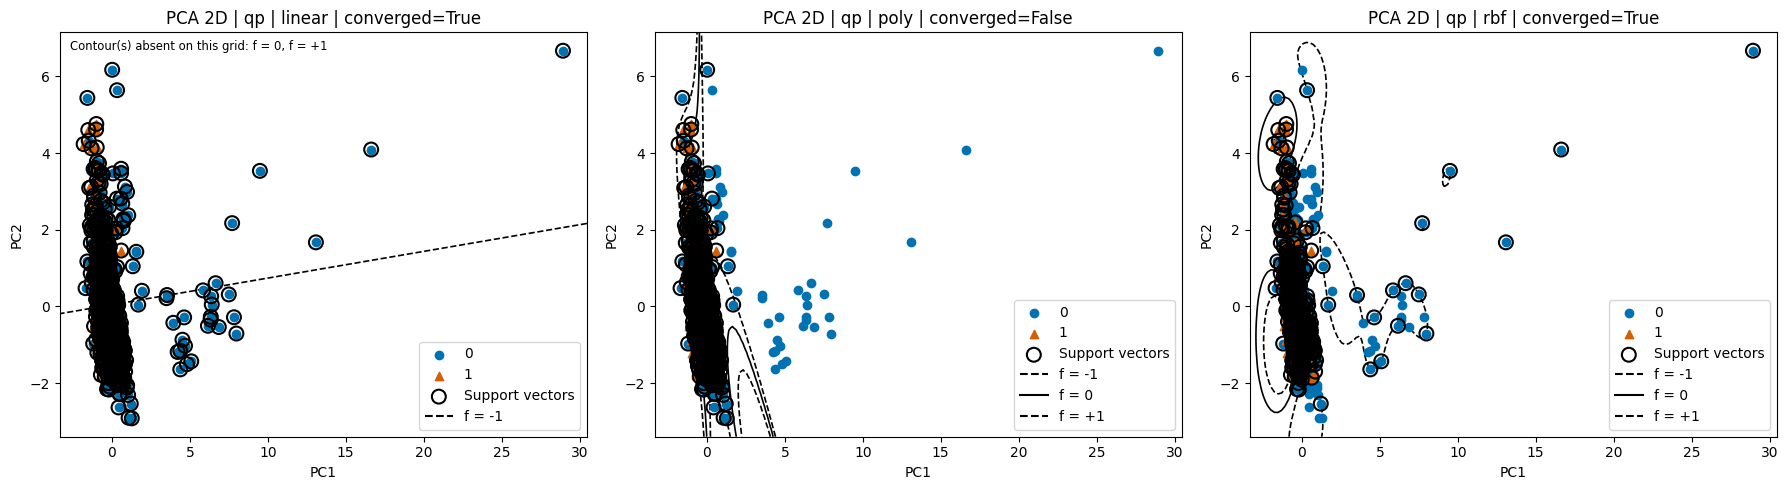

PCA smo/linear: 0.26s, n_iter=234, converged=True


PCA smo/poly: 6.19s, n_iter=9278, converged=True


PCA smo/rbf: 1.35s, n_iter=358, converged=True


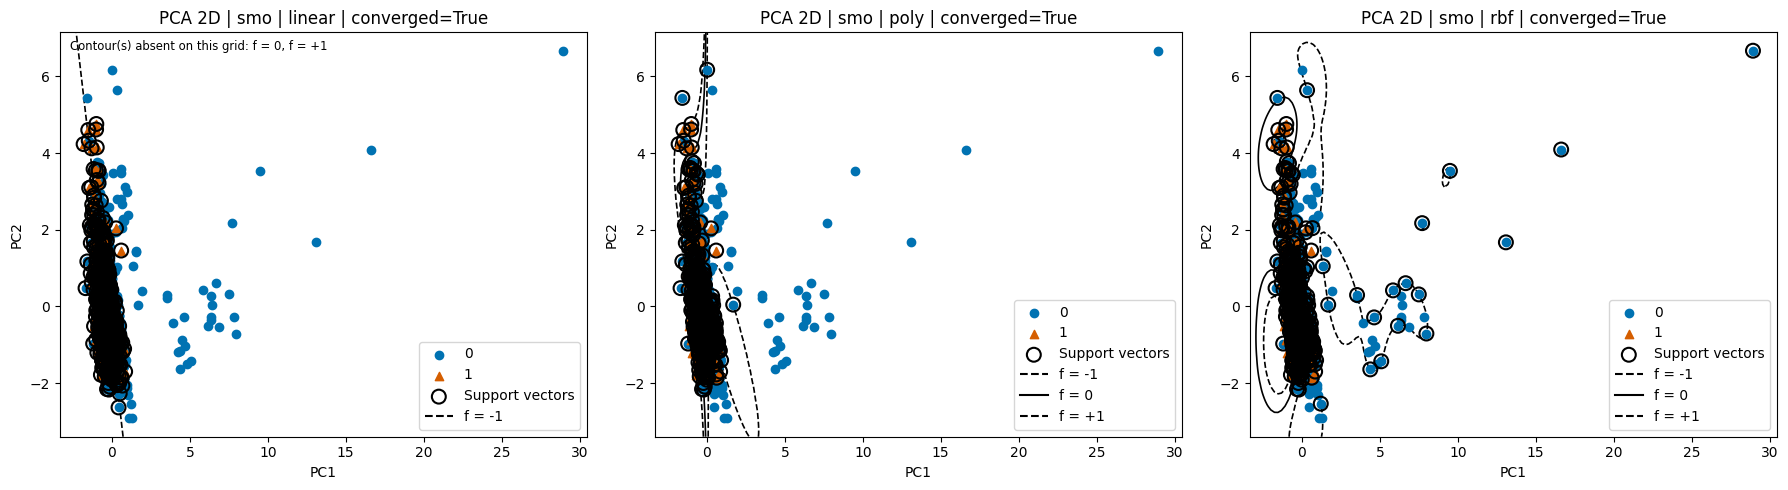

,solver,kernel,train_time,n_iter,converged,fit_status
0,qp,linear,0.644017,323,True,0
1,qp,poly,67.312466,50000,False,1
2,qp,rbf,3.023606,2146,True,0
3,smo,linear,0.261225,234,True,0
4,smo,poly,6.188263,9278,True,0
5,smo,rbf,1.350882,358,True,0


In [31]:
svm_pca = PCA(n_components=2, random_state=SEED)
svm_X_train_2d = svm_pca.fit_transform(svm_X_train)
svm_X_valid_2d = svm_pca.transform(svm_X_valid)
svm_visual_params = {**svm_shared_params, 'gamma': 1 / 2}
svm_visual_models = {}
svm_visual_results = []
svm_plot_paths = {
    'qp': OUTPUT_DIR / 'svm_boundaries_qp.png',
    'smo': OUTPUT_DIR / 'svm_boundaries_smo.png',
}
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
for svm_solver in ('qp', 'smo'):
    svm_figure, svm_axes = plt.subplots(1, 3, figsize=(18, 5))
    for svm_ax, (svm_name, svm_config) in zip(svm_axes, svm_kernel_configs.items()):
        svm_visual_model = SVM(
            **svm_visual_params, **svm_config, solver=svm_solver,
            max_iter=SVM_MAX_ITER, random_state=SEED,
        )
        svm_start = time.perf_counter()
        svm_visual_model.fit(svm_X_train_2d, svm_y_train)
        svm_fit_seconds = time.perf_counter() - svm_start
        svm_visual_models[(svm_solver, svm_name)] = svm_visual_model
        svm_visual_results.append({
            'solver': svm_solver, 'kernel': svm_name,
            'train_time': svm_fit_seconds, 'n_iter': svm_visual_model.n_iter_,
            'converged': svm_visual_model.converged_,
            'fit_status': svm_visual_model.fit_status_,
        })
        print(f'PCA {svm_solver}/{svm_name}: {svm_fit_seconds:.2f}s, '
              f'n_iter={svm_visual_model.n_iter_}, '
              f'converged={svm_visual_model.converged_}')
        plot_svm_boundary(
            svm_visual_model, svm_X_train_2d, svm_y_train, ax=svm_ax,
            title=f'PCA 2D | {svm_solver} | {svm_name} | '
                  f'converged={svm_visual_model.converged_}',
        )
        svm_ax.set(xlabel='PC1', ylabel='PC2')
    svm_figure.tight_layout()
    svm_figure.savefig(svm_plot_paths[svm_solver], dpi=150)
    plt.show()
pd.DataFrame(svm_visual_results)

### Simpan dan muat model
Contoh memakai model SMO Gaussian (rbf) berdimensi asli yang dipilih tetap, bukan pemenang validation. Preprocessor disimpan terpisah agar fitur mentah diproses identik saat prediksi. Hanya muat berkas pickle dari sumber tepercaya karena pemuatan dapat menjalankan kode. Kesamaan transformasi, skor, dan prediksi diperiksa pada contoh validation, tanpa membuat submission Kaggle.

In [32]:
svm_model_path = OUTPUT_DIR / 'svm_smo_gaussian.pkl'
svm_preprocessor_path = OUTPUT_DIR / 'svm_preprocessor.pkl'
svm_saved_model = svm_custom_models[('smo', 'rbf')]
svm_saved_model.save(svm_model_path)
with svm_preprocessor_path.open('wb') as svm_file:
    pickle.dump(svm_preprocessor, svm_file)
svm_loaded_model = SVM.load(svm_model_path)
with svm_preprocessor_path.open('rb') as svm_file:
    svm_loaded_preprocessor = pickle.load(svm_file)
svm_demo_raw = svm_X_raw.iloc[svm_valid_indices[:5]]
svm_demo_X = svm_preprocessor.transform(svm_demo_raw)
svm_reloaded_X = svm_loaded_preprocessor.transform(svm_demo_raw)
svm_demo_predictions = svm_saved_model.predict(svm_demo_X)
svm_reloaded_predictions = svm_loaded_model.predict(svm_reloaded_X)
np.testing.assert_allclose(svm_demo_X, svm_reloaded_X)
np.testing.assert_allclose(
    svm_saved_model.decision_function(svm_demo_X),
    svm_loaded_model.decision_function(svm_reloaded_X),
)
np.testing.assert_array_equal(svm_demo_predictions, svm_reloaded_predictions)
pd.DataFrame({
    'aktual': svm_y_raw.iloc[svm_valid_indices[:5]].to_numpy(),
    'prediksi_awal': svm_demo_predictions,
    'prediksi_muat_ulang': svm_reloaded_predictions,
}, index=svm_demo_raw.index)

,aktual,prediksi_awal,prediksi_muat_ulang
8,0,0,0
11,0,0,0
12,0,0,0
15,0,0,0
16,1,0,0


## Logistic Regression from scratch dan scikit-learn
Model custom memakai NumPy dan objective **mean log-loss + regularisasi**. Empat varian: tanpa penalti, L1, L2, dan Elastic Net. Bias tidak diregularisasi. Full-batch gradient descent dipakai untuk perbandingan ini; `batch_size=1` memilih SGD dan nilai lainnya memilih mini-batch. L1 menggunakan subgradien sehingga bobot tidak dijamin tepat nol. `converged_` berarti perubahan objective kecil selama beberapa epoch, bukan jaminan optimum global telah tercapai.

Referensi tugas: spesifikasi halaman 11?12 dan salindia Logistic Regression perkuliahan. Referensi pembanding dan skala penalti: https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression . Untuk objective custom, **C = 1 / (n_train * reg_strength)** pada scikit-learn tanpa sample/class weights.


In [33]:
logreg_X_raw = train_df.drop(columns=['id', 'is_canceled'])
logreg_y_raw = train_df['is_canceled']
logreg_groups = pd.util.hash_pandas_object(logreg_X_raw, index=False)
logreg_splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
logreg_train_idx, logreg_valid_idx = next(
    logreg_splitter.split(logreg_X_raw, logreg_y_raw, logreg_groups)
)
assert set(logreg_groups.iloc[logreg_train_idx]).isdisjoint(
    logreg_groups.iloc[logreg_valid_idx]
)
logreg_numeric = logreg_X_raw.select_dtypes(include='number').columns.tolist()
logreg_categorical = [c for c in logreg_X_raw.columns if c not in logreg_numeric]
logreg_preprocessor = ColumnTransformer([
    ('numeric', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
    ]), logreg_numeric),
    ('categorical', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
    ]), logreg_categorical),
])
logreg_X_train = logreg_preprocessor.fit_transform(logreg_X_raw.iloc[logreg_train_idx])
logreg_X_valid = logreg_preprocessor.transform(logreg_X_raw.iloc[logreg_valid_idx])
logreg_y_train = logreg_y_raw.iloc[logreg_train_idx].to_numpy()
logreg_y_valid = logreg_y_raw.iloc[logreg_valid_idx].to_numpy()
print('Logreg training:', logreg_X_train.shape, 'validation:', logreg_X_valid.shape)


Logreg training: (21899, 30) validation: (5474, 30)


In [34]:
LOGREG_STRENGTH = 0.001
LOGREG_MAX_ITER = 2000
logreg_custom_models, logreg_library_models, logreg_rows = {}, {}, []
# scikit-learn >=1.8 encodes penalty through l1_ratio/C.
logreg_modern_api = tuple(int(x) for x in sklearn_version.split('.')[:2]) >= (1, 8)
for name, penalty, ratio in [
    ('none', None, 0.0), ('l1', 'l1', 1.0),
    ('l2', 'l2', 0.0), ('elasticnet', 'elasticnet', 0.5),
]:
    custom = LogisticRegressionClassifier(
        penalty=penalty, reg_strength=LOGREG_STRENGTH, l1_ratio=ratio,
        learning_rate=0.1, max_iter=LOGREG_MAX_ITER, tol=1e-7,
        random_state=SEED,
    )
    library_options = dict(solver='saga', max_iter=LOGREG_MAX_ITER,
                           tol=1e-7, random_state=SEED)
    if logreg_modern_api:
        library_options.update(l1_ratio=ratio, C=(np.inf if penalty is None else
            1 / (len(logreg_y_train) * LOGREG_STRENGTH)))
    else:
        library_options.update(penalty=penalty,
            C=1 / (len(logreg_y_train) * LOGREG_STRENGTH))
        if penalty == 'elasticnet':
            library_options['l1_ratio'] = ratio
    library = LogisticRegression(**library_options)
    logreg_custom_models[name], logreg_library_models[name] = custom, library
    for implementation, model in [('custom', custom), ('scikit-learn', library)]:
        started = time.perf_counter()
        model.fit(logreg_X_train, logreg_y_train)
        seconds = time.perf_counter() - started
        predictions = model.predict(logreg_X_valid)
        probabilities = model.predict_proba(logreg_X_valid)[:, 1]
        iterations = int(np.asarray(model.n_iter_).reshape(-1)[0])
        logreg_rows.append({
            'variant': name, 'implementation': implementation,
            'accuracy': accuracy_score(logreg_y_valid, predictions),
            'precision': precision_score(logreg_y_valid, predictions, zero_division=0),
            'recall': recall_score(logreg_y_valid, predictions, zero_division=0),
            'f1': f1_score(logreg_y_valid, predictions, zero_division=0),
            'roc_auc': roc_auc_score(logreg_y_valid, probabilities),
            'log_loss': log_loss(logreg_y_valid, probabilities),
            'fit_seconds': seconds, 'iterations': iterations,
            'converged': model.converged_ if implementation == 'custom' else iterations < LOGREG_MAX_ITER,
            'confusion_matrix': confusion_matrix(logreg_y_valid, predictions).tolist(),
        })
logreg_results = pd.DataFrame(logreg_rows)
logreg_results.to_csv(OUTPUT_DIR / 'logreg_comparison.csv', index=False)
logreg_results


D:\proyek\IF3170_G14_LalapKaoBole\src\models\logreg\logreg.py:145: RuntimeWarning: Logistic regression stopped before convergence
  warnings.warn("Logistic regression stopped before convergence", RuntimeWarning)
C:\Users\Asus\AppData\Roaming\Python\Python313\site-packages\sklearn\linear_model\_logistic.py:1207: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(


C:\Users\Asus\AppData\Roaming\Python\Python313\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


D:\proyek\IF3170_G14_LalapKaoBole\src\models\logreg\logreg.py:145: RuntimeWarning: Logistic regression stopped before convergence
  warnings.warn("Logistic regression stopped before convergence", RuntimeWarning)


D:\proyek\IF3170_G14_LalapKaoBole\src\models\logreg\logreg.py:145: RuntimeWarning: Logistic regression stopped before convergence
  warnings.warn("Logistic regression stopped before convergence", RuntimeWarning)


D:\proyek\IF3170_G14_LalapKaoBole\src\models\logreg\logreg.py:145: RuntimeWarning: Logistic regression stopped before convergence
  warnings.warn("Logistic regression stopped before convergence", RuntimeWarning)


,variant,implementation,accuracy,precision,recall,f1,roc_auc,log_loss,fit_seconds,iterations,converged,confusion_matrix
0,none,custom,0.807819,0.739159,0.632022,0.681405,0.864926,0.423881,7.604348,2000,False,"[[3297, 397], [655, 1125]]"
1,none,scikit-learn,0.806175,0.734202,0.633146,0.679940,0.865289,0.422755,27.057465,2000,False,"[[3286, 408], [653, 1127]]"
2,l1,custom,0.806175,0.737922,0.626404,0.677606,0.864999,0.424683,7.528461,2000,False,"[[3298, 396], [665, 1115]]"
3,l1,scikit-learn,0.807271,0.740864,0.626404,0.678843,0.865116,0.424021,4.262733,269,True,"[[3304, 390], [665, 1115]]"
4,l2,custom,0.807453,0.739762,0.629213,0.680024,0.864966,0.424226,7.503989,2000,False,"[[3300, 394], [660, 1120]]"
5,l2,scikit-learn,0.805992,0.735874,0.629213,0.678377,0.865155,0.423701,9.107806,666,True,"[[3292, 402], [660, 1120]]"
6,elasticnet,custom,0.807453,0.739130,0.630337,0.680412,0.864983,0.424467,7.466244,2000,False,"[[3298, 396], [658, 1122]]"
7,elasticnet,scikit-learn,0.807453,0.740397,0.628090,0.679635,0.865143,0.423875,7.744514,444,True,"[[3302, 392], [662, 1118]]"


### Loss training dan simpan/muat
Grafik menunjukkan objective training masing-masing model; penalti berbeda membuat nilai objective antarvarian tidak langsung sebanding. Jumlah iterasi custom dan SAGA juga tidak setara; gunakan waktu serta metrik validation dalam analisis.

Contoh persistence menggunakan L2 yang ditetapkan sebelumnya. Preprocessor disimpan bersama model, urutan kolom mentah, dan konfigurasi eksperimen. Hanya muat pickle dari sumber tepercaya. Pemilihan hyperparameter lanjutan perlu dilakukan di fold training; tabel validation ini belum merupakan estimasi test independen setelah tuning.


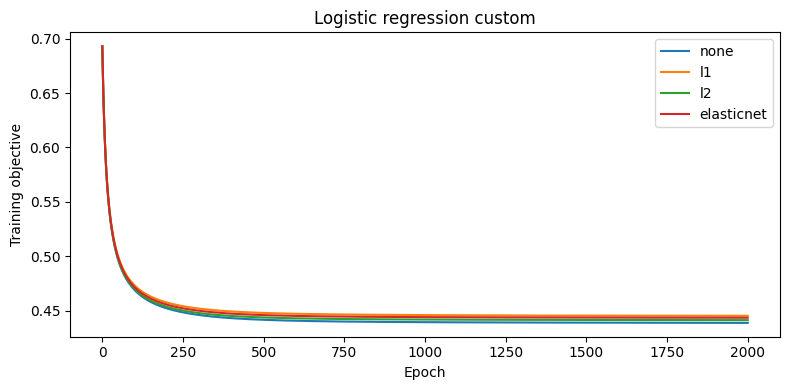

Save/load model dan preprocessing menghasilkan prediksi identik.


In [35]:
fig, ax = plt.subplots(figsize=(8, 4))
for name, model in logreg_custom_models.items():
    ax.plot(model.loss_history_, label=name)
ax.set(xlabel='Epoch', ylabel='Training objective', title='Logistic regression custom')
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'logreg_loss.png', dpi=150)
plt.show()

logreg_saved = logreg_custom_models['l2']
logreg_saved.save(OUTPUT_DIR / 'logreg_l2.pkl')
logreg_bundle = {
    'model': logreg_saved, 'preprocessor': logreg_preprocessor,
    'feature_columns': logreg_X_raw.columns.tolist(),
    'seed': SEED, 'reg_strength': LOGREG_STRENGTH,
    'train_indices': logreg_train_idx, 'validation_indices': logreg_valid_idx,
    'sklearn_version': sklearn_version,
}
with (OUTPUT_DIR / 'logreg_bundle.pkl').open('wb') as file:
    pickle.dump(logreg_bundle, file)
with (OUTPUT_DIR / 'logreg_bundle.pkl').open('rb') as file:
    logreg_restored = pickle.load(file)
logreg_demo_raw = logreg_X_raw.iloc[logreg_valid_idx[:10]]
logreg_demo = logreg_restored['preprocessor'].transform(
    logreg_demo_raw[logreg_restored['feature_columns']]
)
np.testing.assert_array_equal(
    logreg_saved.predict_proba(logreg_X_valid[:10]),
    logreg_restored['model'].predict_proba(logreg_demo),
)
logreg_loaded = LogisticRegressionClassifier.load(OUTPUT_DIR / 'logreg_l2.pkl')
np.testing.assert_array_equal(
    logreg_saved.predict(logreg_X_valid[:10]), logreg_loaded.predict(logreg_X_valid[:10])
)
print('Save/load model dan preprocessing menghasilkan prediksi identik.')


## Naive Bayes
Naive Bayes dibangun dari nol di `src/models/naive_bayes/naive_bayes.py`. Model menghitung frekuensi tiap nilai fitur untuk setiap kelas (dengan Laplace smoothing), lalu memilih kelas dengan skor `log P(kelas) + jumlah log P(fitur | kelas)` terbesar. Nilai kosong (NaN) dilewati saat prediksi dan tidak dihitung saat training, sehingga tidak perlu diimputasi.

Split validation sama dengan SVM (seed 42, 5 fold, baris identik dikelompokkan), tetapi memakai seluruh training split, bukan subset 1000 baris. Seluruh pilihan di bagian ini ditentukan dari validation, bukan dari test.

In [36]:
from models import NaiveBayesClassifier

# Split sama persis dengan SVM (seed, 5 fold, grup baris identik), tetapi memakai seluruh training split.
nb_X_raw = train_df.drop(columns=['is_canceled', 'id'])
nb_y_raw = train_df['is_canceled']
nb_groups = pd.util.hash_pandas_object(nb_X_raw, index=False)
nb_splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
nb_train_idx, nb_valid_idx = next(nb_splitter.split(nb_X_raw, nb_y_raw, nb_groups))
assert set(nb_groups.iloc[nb_train_idx]).isdisjoint(nb_groups.iloc[nb_valid_idx])
nb_y_train = nb_y_raw.iloc[nb_train_idx].to_numpy()
nb_y_valid = nb_y_raw.iloc[nb_valid_idx].to_numpy()
print(f'Train: {len(nb_train_idx)}, validation: {len(nb_valid_idx)}')
print(f'Proporsi batal -> train: {nb_y_train.mean():.3f}, validation: {nb_y_valid.mean():.3f}')

Train: 21899, validation: 5474
Proporsi batal -> train: 0.328, validation: 0.325


### Persiapan fitur
Fitur dibagi tiga kelompok:
- **Teks** (`meal_package`, `room_category`, `booking_channel`): diubah menjadi kode angka berdasarkan kategori di training. Kategori yang tidak pernah muncul di training menjadi NaN dan dilewati.
- **Hitungan bernilai sedikit** (misalnya `num_adults`, `arrival_month`, `special_requests`): langsung diperlakukan sebagai kategorikal.
- **Kontinu atau bernilai banyak** (`days_before_arrival`, `nightly_rate_idr`, `prior_completed_bookings`, `arrival_day`): dicoba dengan dua cara, distribusi Gaussian per kelas atau binning kuantil menjadi kategorikal.

Kode kategori dan batas bin dipelajari hanya dari data training.

In [37]:
nb_text_features = ['meal_package', 'room_category', 'booking_channel']
nb_count_features = [
    'num_adults', 'num_children', 'weekend_nights', 'weekday_nights', 'needs_parking',
    'arrival_year', 'arrival_month', 'is_returning_guest', 'prior_cancellations', 'special_requests',
]
nb_continuous_features = ['days_before_arrival', 'nightly_rate_idr', 'prior_completed_bookings', 'arrival_day']


def nb_fit_preprocessing(raw, n_bins):
    # Semua yang dipelajari (kode teks, batas bin) hanya dari data training
    params = {'n_bins': n_bins, 'text_mapping': {}, 'bin_edges': {}}
    for col in nb_text_features:
        categories = sorted(raw[col].dropna().unique())
        params['text_mapping'][col] = {name: i for i, name in enumerate(categories)}
    quantiles = np.linspace(0, 1, n_bins + 1)[1:-1]
    for col in nb_continuous_features:
        params['bin_edges'][col] = np.unique(np.nanquantile(raw[col], quantiles))
    return params


def nb_transform(raw, params, continuous_mode):
    # continuous_mode: 'binning', 'gaussian' (nilai asli), atau 'gaussian_log' (log1p)
    columns = []
    for col in nb_text_features:
        # teks -> angka, kategori yang tidak pernah muncul di training jadi NaN (dilewati)
        columns.append(raw[col].map(params['text_mapping'][col]).to_numpy(dtype=float))
    for col in nb_count_features:
        columns.append(raw[col].to_numpy(dtype=float))
    for col in nb_continuous_features:
        values = raw[col].to_numpy(dtype=float)
        if continuous_mode == 'binning':
            codes = np.digitize(values, params['bin_edges'][col]).astype(float)
            codes[np.isnan(values)] = np.nan
            values = codes
        elif continuous_mode == 'gaussian_log':
            values = np.log1p(values)
        columns.append(values)
    return np.column_stack(columns)


def nb_feature_types(continuous_mode):
    n_discrete = len(nb_text_features) + len(nb_count_features)
    kind = 'categorical' if continuous_mode == 'binning' else 'gaussian'
    return ['categorical'] * n_discrete + [kind] * len(nb_continuous_features)


nb_raw_train = nb_X_raw.iloc[nb_train_idx]
nb_raw_valid = nb_X_raw.iloc[nb_valid_idx]
print('Fitur teks:', len(nb_text_features), '| fitur hitungan:', len(nb_count_features),
      '| fitur kontinu:', len(nb_continuous_features))

Fitur teks: 3 | fitur hitungan: 10 | fitur kontinu: 4


### Gaussian atau binning untuk fitur kontinu
Semua konfigurasi memakai `alpha = 1`. `gaussian_log` menerapkan `log1p` sebelum Gaussian karena beberapa fitur sangat miring ke kanan.

In [38]:
def nb_evaluate(model, X_valid, y_valid):
    predictions = model.predict(X_valid)
    proba_cancel = model.predict_proba(X_valid)[:, 1]
    return {
        'accuracy': accuracy_score(y_valid, predictions),
        'precision': precision_score(y_valid, predictions, zero_division=0),
        'recall': recall_score(y_valid, predictions, zero_division=0),
        'f1': f1_score(y_valid, predictions, zero_division=0),
        'roc_auc': roc_auc_score(y_valid, proba_cancel),
    }


nb_mode_settings = [
    ('gaussian', None), ('gaussian_log', None),
    ('binning', 5), ('binning', 10), ('binning', 20),
]
nb_mode_results = []
for nb_mode, nb_bins in nb_mode_settings:
    nb_params = nb_fit_preprocessing(nb_raw_train, nb_bins or 10)
    nb_Xtr = nb_transform(nb_raw_train, nb_params, nb_mode)
    nb_Xva = nb_transform(nb_raw_valid, nb_params, nb_mode)
    nb_model = NaiveBayesClassifier(alpha=1.0, feature_types=nb_feature_types(nb_mode))
    nb_start = time.perf_counter()
    nb_model.fit(nb_Xtr, nb_y_train)
    nb_fit_seconds = time.perf_counter() - nb_start
    nb_row = {'continuous_mode': nb_mode, 'n_bins': nb_bins, 'fit_seconds': nb_fit_seconds}
    nb_row.update(nb_evaluate(nb_model, nb_Xva, nb_y_valid))
    nb_mode_results.append(nb_row)
nb_mode_table = pd.DataFrame(nb_mode_results)
nb_mode_table

,continuous_mode,n_bins,fit_seconds,accuracy,precision,recall,f1,roc_auc
0,gaussian,NaN,0.044569,0.511144,0.397764,0.979213,0.565725,0.835881
1,gaussian_log,NaN,0.046460,0.476617,0.380952,0.975281,0.547893,0.807165
2,binning,5.0,0.049449,0.786810,0.693865,0.616292,0.652782,0.839991
3,binning,10.0,0.067717,0.785532,0.689612,0.619101,0.652457,0.840237
4,binning,20.0,0.077511,0.786810,0.689081,0.627528,0.656866,0.842529


Gaussian pada nilai asli menghasilkan accuracy sekitar 0,51 dengan recall 0,97, artinya hampir semua booking ditebak batal. Binning jauh lebih baik: accuracy sekitar 0,78 dan F1 sekitar 0,65. Di antara 5, 10, dan 20 bin selisihnya kecil. 20 bin memiliki `roc_auc` tertinggi (0,832), sehingga dipakai pada langkah berikutnya.

### Fitur kontinu mana yang bermasalah pada Gaussian
Gaussian dipasang pada satu fitur kontinu sekali waktu, sementara tiga fitur kontinu lainnya tetap di-binning.

In [39]:
# Gaussian dipasang pada satu fitur kontinu saja, fitur kontinu lain tetap di-binning (20 bin)
nb_params = nb_fit_preprocessing(nb_raw_train, 20)
nb_Xtr_binned = nb_transform(nb_raw_train, nb_params, 'binning')
nb_Xva_binned = nb_transform(nb_raw_valid, nb_params, 'binning')
nb_Xtr_gauss = nb_transform(nb_raw_train, nb_params, 'gaussian')
nb_Xva_gauss = nb_transform(nb_raw_valid, nb_params, 'gaussian')
nb_first_continuous = len(nb_text_features) + len(nb_count_features)

nb_per_feature = []
for k, nb_feature in enumerate(nb_continuous_features):
    col = nb_first_continuous + k
    Xtr = nb_Xtr_binned.copy()
    Xva = nb_Xva_binned.copy()
    Xtr[:, col] = nb_Xtr_gauss[:, col]
    Xva[:, col] = nb_Xva_gauss[:, col]
    types = ['categorical'] * Xtr.shape[1]
    types[col] = 'gaussian'
    model = NaiveBayesClassifier(alpha=1.0, feature_types=types).fit(Xtr, nb_y_train)
    nb_row = {'fitur_gaussian': nb_feature}
    nb_row.update(nb_evaluate(model, Xva, nb_y_valid))
    nb_per_feature.append(nb_row)
pd.DataFrame(nb_per_feature)

,fitur_gaussian,accuracy,precision,recall,f1,roc_auc
0,days_before_arrival,0.782061,0.704530,0.567978,0.628927,0.834178
1,nightly_rate_idr,0.789003,0.697660,0.619663,0.656352,0.842976
2,prior_completed_bookings,0.512605,0.398305,0.976966,0.565897,0.842561
3,arrival_day,0.788820,0.694757,0.625281,0.658190,0.843057


Kegagalan Gaussian berasal dari `prior_completed_bookings`: hampir semua nilainya 0, sehingga varians per kelas sangat kecil dan nilai bukan nol kemungkinan menghasilkan likelihood yang ekstrem, yang mendorong prediksi ke kelas batal. `days_before_arrival` juga sedikit lebih buruk dengan Gaussian (`roc_auc` sekitar 0,822 dibanding 0,833), sedangkan `nightly_rate_idr` sedikit lebih baik (F1 sekitar 0,651 dibanding 0,647) dan `arrival_day` tidak berpengaruh. Asumsi distribusi normal tidak cocok untuk fitur yang sangat miring, sedangkan binning tidak membutuhkan asumsi bentuk distribusi, sehingga seluruh fitur kontinu di-binning (20 bin).

### Pemilihan alpha
`alpha` adalah hitungan pura-pura yang ditambahkan ke setiap nilai agar tidak ada peluang yang bernilai 0. Nilainya dicoba pada validation saja.

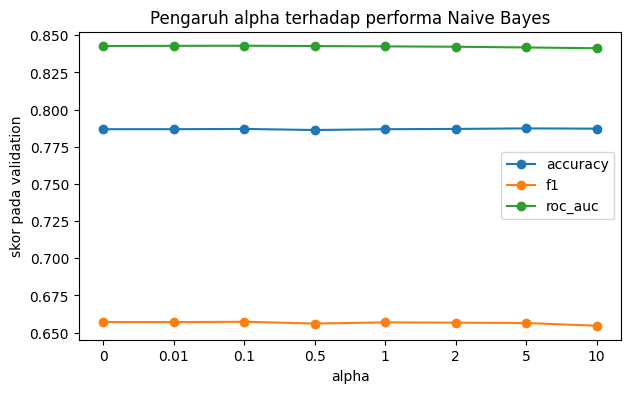

alpha terpilih: 2.0


,alpha,accuracy,precision,recall,f1,roc_auc
0,0.00,0.786810,0.688848,0.628090,0.657067,0.842753
1,0.01,0.786810,0.688848,0.628090,0.657067,0.842880
2,0.10,0.786993,0.689273,0.628090,0.657260,0.842965
3,0.50,0.786262,0.688039,0.626966,0.656085,0.842718
4,1.00,0.786810,0.689081,0.627528,0.656866,0.842529
5,2.00,0.786993,0.689975,0.626404,0.656655,0.842279
6,5.00,0.787358,0.691542,0.624719,0.656434,0.841794
7,10.00,0.787176,0.693032,0.620225,0.654610,0.841265


In [40]:
NB_MODE = 'binning'
NB_BINS = 20
nb_params = nb_fit_preprocessing(nb_raw_train, NB_BINS or 10)
nb_Xtr = nb_transform(nb_raw_train, nb_params, NB_MODE)
nb_Xva = nb_transform(nb_raw_valid, nb_params, NB_MODE)

nb_alphas = [0, 0.01, 0.1, 0.5, 1, 2, 5, 10]
nb_alpha_results = []
for nb_alpha in nb_alphas:
    nb_model = NaiveBayesClassifier(alpha=nb_alpha, feature_types=nb_feature_types(NB_MODE))
    nb_model.fit(nb_Xtr, nb_y_train)
    nb_row = {'alpha': nb_alpha}
    nb_row.update(nb_evaluate(nb_model, nb_Xva, nb_y_valid))
    nb_alpha_results.append(nb_row)
nb_alpha_table = pd.DataFrame(nb_alpha_results)

fig, ax = plt.subplots(figsize=(7, 4))
positions = range(len(nb_alphas))
for metric in ['accuracy', 'f1', 'roc_auc']:
    ax.plot(positions, nb_alpha_table[metric], marker='o', label=metric)
ax.set_xticks(list(positions))
ax.set_xticklabels([str(a) for a in nb_alphas])
ax.set_xlabel('alpha')
ax.set_ylabel('skor pada validation')
ax.set_title('Pengaruh alpha terhadap performa Naive Bayes')
ax.legend()
plt.show()

# Selisih antar alpha sangat kecil, jadi dipilih alpha terbesar yang roc_auc-nya masih
# dalam 0.001 dari yang terbaik (smoothing lebih besar lebih aman untuk nilai langka)
nb_best_auc = nb_alpha_table['roc_auc'].max()
NB_ALPHA = float(nb_alpha_table[nb_alpha_table['roc_auc'] >= nb_best_auc - 0.001]['alpha'].max())
print('alpha terpilih:', NB_ALPHA)
nb_alpha_table

Pengaruh `alpha` sangat kecil (`roc_auc` berkisar 0,831 sampai 0,833) karena training memiliki 21.897 baris, sehingga hitungan nyata jauh lebih besar daripada hitungan pura-pura. Karena itu dipilih `alpha` terbesar yang `roc_auc`-nya masih dalam 0,001 dari yang terbaik, yaitu 1,0. `alpha = 0` tidak dipakai walaupun sedikit lebih tinggi: tanpa smoothing, satu nilai yang belum pernah terlihat di sebuah kelas langsung membuat skor kelas itu menjadi 0. Skor validation di atas sedikit optimistis karena `alpha` dan jumlah bin dipilih dari validation yang sama.

### Perbandingan dengan scikit-learn
Dua perbandingan dengan input yang identik: kategorikal melawan `CategoricalNB`, dan Gaussian melawan `GaussianNB` (dengan `var_smoothing = 0` agar rumusnya sama). scikit-learn tidak menerima NaN, jadi untuk perbandingan ini NaN diisi dulu. Model buatan sendiri sebenarnya menangani NaN langsung.

In [41]:
# Bandingkan dengan scikit-learn pada input yang identik. sklearn tidak menerima NaN,
# jadi untuk perbandingan ini NaN diisi dulu (modus untuk diskret, median untuk kontinu).
nb_params = nb_fit_preprocessing(nb_raw_train, 10)
nb_Xtr_bin = nb_transform(nb_raw_train, nb_params, 'binning')
nb_Xva_bin = nb_transform(nb_raw_valid, nb_params, 'binning')

# CategoricalNB butuh kode 0..K-1 per kolom. Nilai asli seperti arrival_year=2024 akan membuat
# jumlah kategorinya (K) ikut membengkak, jadi tiap kolom dikodekan ulang dari nilai training.
# Nilai validation yang tidak pernah ada di training dijadikan NaN lalu ikut diisi modus.
nb_Xtr_codes = np.full(nb_Xtr_bin.shape, np.nan)
nb_Xva_codes = np.full(nb_Xva_bin.shape, np.nan)
for j in range(nb_Xtr_bin.shape[1]):
    known_values = np.unique(nb_Xtr_bin[~np.isnan(nb_Xtr_bin[:, j]), j])
    code_of = {value: code for code, value in enumerate(known_values)}
    nb_Xtr_codes[:, j] = [code_of.get(v, np.nan) for v in nb_Xtr_bin[:, j]]
    nb_Xva_codes[:, j] = [code_of.get(v, np.nan) for v in nb_Xva_bin[:, j]]
nb_filler = SimpleImputer(strategy='most_frequent')
nb_Xtr_bin_filled = nb_filler.fit_transform(nb_Xtr_codes).astype(int)
nb_Xva_bin_filled = nb_filler.transform(nb_Xva_codes).astype(int)

nb_categories = nb_Xtr_bin_filled.max(axis=0) + 1
nb_sk_cat = CategoricalNB(alpha=1.0, min_categories=nb_categories).fit(nb_Xtr_bin_filled, nb_y_train)
nb_own_cat = NaiveBayesClassifier(alpha=1.0).fit(nb_Xtr_bin_filled, nb_y_train)
nb_diff_cat = np.abs(nb_sk_cat.predict_proba(nb_Xva_bin_filled) - nb_own_cat.predict_proba(nb_Xva_bin_filled)).max()

# Fitur kontinu saja untuk GaussianNB (var_smoothing=0 agar rumusnya sama persis)
nb_Xtr_g = nb_transform(nb_raw_train, nb_params, 'gaussian_log')[:, -len(nb_continuous_features):]
nb_Xva_g = nb_transform(nb_raw_valid, nb_params, 'gaussian_log')[:, -len(nb_continuous_features):]
nb_median = SimpleImputer(strategy='median')
nb_Xtr_g = nb_median.fit_transform(nb_Xtr_g)
nb_Xva_g = nb_median.transform(nb_Xva_g)
nb_sk_gauss = GaussianNB(var_smoothing=0).fit(nb_Xtr_g, nb_y_train)
nb_own_gauss = NaiveBayesClassifier(feature_types=['gaussian'] * nb_Xtr_g.shape[1], var_smoothing=0).fit(nb_Xtr_g, nb_y_train)
nb_diff_gauss = np.abs(nb_sk_gauss.predict_proba(nb_Xva_g) - nb_own_gauss.predict_proba(nb_Xva_g)).max()

print(f'Selisih maksimum predict_proba, kategorikal vs CategoricalNB: {nb_diff_cat:.2e}')
print(f'Selisih maksimum predict_proba, Gaussian vs GaussianNB:       {nb_diff_gauss:.2e}')
nb_compare = []
for nb_name, nb_pair_model, nb_pair_X in [
    ('CategoricalNB (sklearn)', nb_sk_cat, nb_Xva_bin_filled), ('Buatan sendiri (kategorikal)', nb_own_cat, nb_Xva_bin_filled),
    ('GaussianNB (sklearn)', nb_sk_gauss, nb_Xva_g), ('Buatan sendiri (Gaussian)', nb_own_gauss, nb_Xva_g),
]:
    nb_row = {'model': nb_name}
    nb_row.update(nb_evaluate(nb_pair_model, nb_pair_X, nb_y_valid))
    nb_compare.append(nb_row)
pd.DataFrame(nb_compare)

Selisih maksimum predict_proba, kategorikal vs CategoricalNB: 4.00e-15
Selisih maksimum predict_proba, Gaussian vs GaussianNB:       3.13e-13


,model,accuracy,precision,recall,f1,roc_auc
0,CategoricalNB (sklearn),0.787541,0.691973,0.624719,0.656628,0.840813
1,Buatan sendiri (kategorikal),0.787541,0.691973,0.624719,0.656628,0.840813
2,GaussianNB (sklearn),0.410851,0.353419,0.978652,0.519302,0.750986
3,Buatan sendiri (Gaussian),0.410851,0.353419,0.978652,0.519302,0.750986


Selisih maksimum `predict_proba` hanya sekitar 1e-15 untuk kategorikal dan 1e-13 untuk Gaussian, jadi hasil implementasi sendiri sama dengan scikit-learn. Perbedaan yang tersisa hanya pada penanganan NaN, yang tidak didukung scikit-learn, dan pada `var_smoothing`: scikit-learn menambahkan varians terbesar dari semua fitur, sedangkan model ini memakai varians tiap kolom.

### Simpan dan muat model
Parameter preprocessing (kode kategori dan batas bin) disimpan terpisah dari model agar fitur mentah diproses identik saat prediksi. Hanya muat berkas pickle dari sumber tepercaya, karena pemuatan dapat menjalankan kode.

In [42]:
nb_final_params = nb_fit_preprocessing(nb_raw_train, NB_BINS or 10)
nb_final_model = NaiveBayesClassifier(alpha=NB_ALPHA, feature_types=nb_feature_types(NB_MODE))
nb_final_model.fit(nb_transform(nb_raw_train, nb_final_params, NB_MODE), nb_y_train)

nb_model_path = OUTPUT_DIR / 'naive_bayes.pkl'
nb_params_path = OUTPUT_DIR / 'naive_bayes_preprocessing.pkl'
nb_final_model.save(nb_model_path)
with nb_params_path.open('wb') as nb_file:
    pickle.dump(nb_final_params, nb_file)

nb_loaded_model = NaiveBayesClassifier.load(nb_model_path)
with nb_params_path.open('rb') as nb_file:
    nb_loaded_params = pickle.load(nb_file)

nb_demo_raw = nb_raw_valid.iloc[:5]
nb_demo_before = nb_final_model.predict_proba(nb_transform(nb_demo_raw, nb_final_params, NB_MODE))
nb_demo_after = nb_loaded_model.predict_proba(nb_transform(nb_demo_raw, nb_loaded_params, NB_MODE))
np.testing.assert_allclose(nb_demo_before, nb_demo_after)
pd.DataFrame({
    'aktual': nb_y_valid[:5],
    'P(batal) awal': nb_demo_before[:, 1].round(4),
    'P(batal) muat ulang': nb_demo_after[:, 1].round(4),
}, index=nb_demo_raw.index)

,aktual,P(batal) awal,P(batal) muat ulang
8,0,0.0563,0.0563
11,0,0.0313,0.0313
12,0,0.0262,0.0262
15,0,0.0511,0.0511
16,1,0.3056,0.3056


## K-Nearest Neighbors (KNN)
KNN dibangun dari nol di src/models/knn/knn.py. Model ini tidak mempelajari parameter apa pun saat training. Seluruh data training hanya disimpan, lalu setiap data baru diklasifikasikan dengan melihat k data training yang jaraknya paling dekat. Jarak yang dipakai adalah jarak Euclidean.

Ada dua cara menggabungkan suara tetangga. Pada bobot uniform, setiap tetangga bernilai satu suara. Pada bobot distance, suara tetangga dibagi jaraknya sehingga tetangga yang lebih dekat lebih berpengaruh. Jika ada tetangga dengan jarak nol, hanya tetangga tersebut yang dihitung. Jika jumlah suara seri, kelas pertama yang dipilih.

Menghitung jarak ke seluruh data training sekaligus membutuhkan memori sekitar 30 GB untuk validation set. Karena itu jarak dihitung per batch 512 baris. Hasilnya tetap sama persis dengan perhitungan langsung.

Split validation sama dengan model lain (seed 42, 5 fold, baris identik dikelompokkan) dan memakai seluruh training split. Metrik utama yang dipakai adalah F1 macro, sama dengan metrik leaderboard Kaggle.

In [43]:
from models import KNNClassifier
from sklearn.preprocessing import FunctionTransformer

knn_X_raw = train_df.drop(columns=['id', 'is_canceled'])
knn_y_raw = train_df['is_canceled'].to_numpy()
knn_groups = pd.util.hash_pandas_object(knn_X_raw, index=False)
knn_splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
knn_train_idx, knn_valid_idx = next(knn_splitter.split(knn_X_raw, knn_y_raw, knn_groups))
assert set(knn_groups.iloc[knn_train_idx]).isdisjoint(knn_groups.iloc[knn_valid_idx])
knn_y_train, knn_y_valid = knn_y_raw[knn_train_idx], knn_y_raw[knn_valid_idx]
print(f'Train: {len(knn_train_idx)}, validation: {len(knn_valid_idx)}')

Train: 21899, validation: 5474


### Preprocessing
KNN hanya membandingkan jarak, sehingga skala fitur sangat menentukan hasil. Tanpa scaling, nightly_rate_idr yang bernilai jutaan akan menguasai jarak dan fitur lain hampir tidak berpengaruh. Nilai kosong diisi median untuk fitur numerik dan modus untuk fitur kategorikal, lalu fitur kategorikal di-one-hot-encode.

Tiga cara scaling dicoba.
- **standard** mengubah setiap fitur numerik menjadi rata-rata 0 dan simpangan baku 1.
- **minmax** memetakan setiap fitur numerik ke rentang 0 sampai 1, sama dengan rentang hasil one-hot.
- **log_standard** menerapkan log1p pada fitur yang sangat miring (days_before_arrival, nightly_rate_idr, prior_completed_bookings, prior_cancellations) sebelum standard scaling.

Semua parameter preprocessing dipelajari hanya dari training split.

In [44]:
knn_numeric = knn_X_raw.select_dtypes(include='number').columns.tolist()
knn_categorical = [col for col in knn_X_raw.columns if col not in knn_numeric]
knn_skewed = ['days_before_arrival', 'nightly_rate_idr', 'prior_completed_bookings', 'prior_cancellations']


def knn_make_preprocessor(scaling):
    def numeric_pipeline(log=False):
        steps = [('imputer', SimpleImputer(strategy='median'))]
        if log:
            steps.append(('log', FunctionTransformer(np.log1p)))
        steps.append(('scaler', MinMaxScaler() if scaling == 'minmax' else StandardScaler()))
        return Pipeline(steps)

    if scaling == 'log_standard':
        others = [col for col in knn_numeric if col not in knn_skewed]
        numeric_parts = [('skewed', numeric_pipeline(log=True), knn_skewed),
                         ('numeric', numeric_pipeline(), others)]
    else:
        numeric_parts = [('numeric', numeric_pipeline(), knn_numeric)]
    categorical = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
    ])
    return ColumnTransformer(numeric_parts + [('categorical', categorical, knn_categorical)])


def knn_evaluate(model, X, y):
    probabilities = model.predict_proba(X)[:, 1]
    predictions = (probabilities > 0.5).astype(int)  # sama dengan predict(), seri dimenangkan kelas 0
    return {
        'accuracy': accuracy_score(y, predictions),
        'precision': precision_score(y, predictions, zero_division=0),
        'recall': recall_score(y, predictions, zero_division=0),
        'f1': f1_score(y, predictions, zero_division=0),
        'f1_macro': f1_score(y, predictions, average='macro'),
        'roc_auc': roc_auc_score(y, probabilities),
    }

### Pemilihan scaling, k, dan bobot
Setiap kombinasi scaling, jumlah tetangga k, dan cara pembobotan dievaluasi pada validation. k yang kecil membuat model sangat peka terhadap satu atau dua tetangga, sedangkan k yang besar membuat batas keputusan lebih halus tetapi bisa ikut terpengaruh data yang jauh.

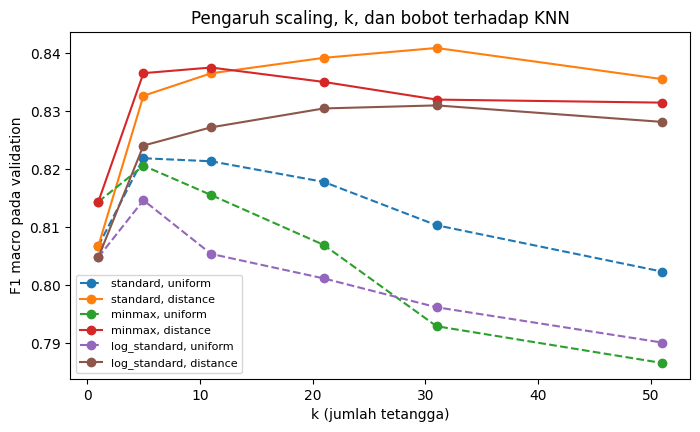

Terpilih: scaling standard, k = 31, bobot distance


,scaling,k,weights,accuracy,precision,recall,f1,f1_macro,roc_auc
0,standard,31,distance,0.862989,0.810990,0.754494,0.781723,0.840941,0.922777
1,standard,21,distance,0.860979,0.803093,0.758427,0.780121,0.839239,0.922999
2,minmax,11,distance,0.859335,0.798817,0.758427,0.778098,0.837565,0.919646
3,minmax,5,distance,0.857691,0.789809,0.766292,0.777873,0.836591,0.908884
4,standard,11,distance,0.858056,0.793446,0.761798,0.777300,0.836565,0.917902
5,standard,51,distance,0.859518,0.814953,0.734831,0.772821,0.835571,0.920716
6,minmax,21,distance,0.857691,0.800240,0.749438,0.774006,0.835077,0.920414
7,standard,5,distance,0.854220,0.783815,0.761798,0.772650,0.832681,0.904187


In [45]:
KNN_SCALINGS = ['standard', 'minmax', 'log_standard']
KNN_KS = [1, 5, 11, 21, 31, 51]
KNN_WEIGHT_OPTIONS = ['uniform', 'distance']

knn_grid_rows = []
for scaling in KNN_SCALINGS:
    preprocessor = knn_make_preprocessor(scaling)
    X_train = preprocessor.fit_transform(knn_X_raw.iloc[knn_train_idx])
    X_valid = preprocessor.transform(knn_X_raw.iloc[knn_valid_idx])
    for k in KNN_KS:
        for weights in KNN_WEIGHT_OPTIONS:
            model = KNNClassifier(n_neighbors=k, weights=weights).fit(X_train, knn_y_train)
            knn_grid_rows.append({'scaling': scaling, 'k': k, 'weights': weights,
                                  **knn_evaluate(model, X_valid, knn_y_valid)})
knn_grid = pd.DataFrame(knn_grid_rows)

fig, ax = plt.subplots(figsize=(8, 4.5))
for (scaling, weights), part in knn_grid.groupby(['scaling', 'weights'], sort=False):
    ax.plot(part['k'], part['f1_macro'], marker='o', linestyle='-' if weights == 'distance' else '--',
            label=f'{scaling}, {weights}')
ax.set_xlabel('k (jumlah tetangga)')
ax.set_ylabel('F1 macro pada validation')
ax.set_title('Pengaruh scaling, k, dan bobot terhadap KNN')
ax.legend(fontsize=8)
plt.show()

knn_best = knn_grid.loc[knn_grid['f1_macro'].idxmax()]
KNN_SCALING, KNN_K, KNN_WEIGHTS = knn_best['scaling'], int(knn_best['k']), knn_best['weights']
print(f'Terpilih: scaling {KNN_SCALING}, k = {KNN_K}, bobot {KNN_WEIGHTS}')
knn_grid.sort_values('f1_macro', ascending=False).head(8).reset_index(drop=True)

#### Insight
- Bobot distance selalu sama atau lebih baik daripada uniform. Pada bobot uniform, F1 macro turun saat k membesar hingga sekitar 0,79 pada k = 51, sedangkan bobot distance tetap di kisaran 0,83 sampai 0,84 karena tetangga yang jauh hanya mendapat suara kecil.
- Standard scaling dengan k = 31 memberi F1 macro tertinggi, yaitu 0,841. Minmax paling baik 0,838 pada k = 11 sehingga selisih keduanya kecil.
- log_standard paling buruk pada hampir semua k. Log memperkecil perbedaan lead time dan harga yang besar, padahal perbedaan itu termasuk sinyal terkuat untuk membedakan booking yang batal.

### Perbandingan dengan scikit-learn
Model terpilih dibandingkan dengan KNeighborsClassifier dari scikit-learn dengan parameter yang sama dan pencarian brute force. Hasil keduanya hanya bisa berbeda ketika ada beberapa tetangga dengan jarak yang sama persis di batas tetangga ke-k, karena urutan pemilihan tetangga yang seri bisa berbeda.

In [46]:
knn_preprocessor = knn_make_preprocessor(KNN_SCALING)
knn_X_train = knn_preprocessor.fit_transform(knn_X_raw.iloc[knn_train_idx])
knn_X_valid = knn_preprocessor.transform(knn_X_raw.iloc[knn_valid_idx])

knn_model = KNNClassifier(n_neighbors=KNN_K, weights=KNN_WEIGHTS)
knn_sklearn = KNeighborsClassifier(n_neighbors=KNN_K, weights=KNN_WEIGHTS, algorithm='brute')
knn_compare, knn_probabilities = [], {}
for knn_name, knn_candidate in [('KNNClassifier (custom)', knn_model), ('KNeighborsClassifier (scikit-learn)', knn_sklearn)]:
    knn_start = time.perf_counter()
    knn_candidate.fit(knn_X_train, knn_y_train)
    knn_probabilities[knn_name] = knn_candidate.predict_proba(knn_X_valid)[:, 1]
    knn_seconds = time.perf_counter() - knn_start
    knn_compare.append({'model': knn_name, **knn_evaluate(knn_candidate, knn_X_valid, knn_y_valid),
                        'fit_predict_seconds': knn_seconds})

knn_diff = np.abs(knn_probabilities['KNNClassifier (custom)'] - knn_probabilities['KNeighborsClassifier (scikit-learn)'])
print(f'Selisih maksimum P(batal): {knn_diff.max():.4f}')
print(f'Baris validation dengan P(batal) berbeda: {(knn_diff > 1e-9).sum()} dari {len(knn_diff)}')
pd.DataFrame(knn_compare)

Selisih maksimum P(batal): 0.0277
Baris validation dengan P(batal) berbeda: 2 dari 5474


,model,accuracy,precision,recall,f1,f1_macro,roc_auc,fit_predict_seconds
0,KNNClassifier (custom),0.862989,0.81099,0.754494,0.781723,0.840941,0.922777,2.712777
1,KNeighborsClassifier (scikit-learn),0.862989,0.81099,0.754494,0.781723,0.840941,0.922774,0.390783


### Model final untuk submisi
Model final memakai scaling, k, dan bobot terpilih, tetapi menyimpan seluruh data train.csv sebagai tetangga. KNN tidak memiliki proses training yang bisa overfit pada data tertentu, jadi menambah data hanya memperbanyak tetangga yang bisa dicari. Preprocessing juga dipelajari ulang dari seluruh train.csv.

In [47]:
knn_final_preprocessor = knn_make_preprocessor(KNN_SCALING)
knn_final_model = KNNClassifier(n_neighbors=KNN_K, weights=KNN_WEIGHTS)
knn_final_model.fit(knn_final_preprocessor.fit_transform(knn_X_raw), knn_y_raw)
print(f'Model final menyimpan {len(knn_y_raw)} data training dengan {knn_X_train.shape[1]} fitur')

Model final menyimpan 27373 data training dengan 30 fitur


### Simpan dan muat model
Preprocessor disimpan terpisah dari model agar data mentah diproses dengan cara yang sama saat prediksi. Hanya muat berkas pickle dari sumber tepercaya, karena pemuatan dapat menjalankan kode.

In [48]:
knn_model_path = OUTPUT_DIR / 'knn.pkl'
knn_preprocessor_path = OUTPUT_DIR / 'knn_preprocessor.pkl'
knn_final_model.save(knn_model_path)
with knn_preprocessor_path.open('wb') as knn_file:
    pickle.dump(knn_final_preprocessor, knn_file)

knn_loaded_model = KNNClassifier.load(knn_model_path)
with knn_preprocessor_path.open('rb') as knn_file:
    knn_loaded_preprocessor = pickle.load(knn_file)

knn_demo_raw = knn_X_raw.iloc[knn_valid_idx[:5]]
knn_demo_before = knn_final_model.predict_proba(knn_final_preprocessor.transform(knn_demo_raw))
knn_demo_after = knn_loaded_model.predict_proba(knn_loaded_preprocessor.transform(knn_demo_raw))
np.testing.assert_allclose(knn_demo_before, knn_demo_after)
pd.DataFrame({
    'aktual': knn_y_valid[:5],
    'P(batal) awal': knn_demo_before[:, 1].round(4),
    'P(batal) muat ulang': knn_demo_after[:, 1].round(4),
}, index=knn_demo_raw.index)

,aktual,P(batal) awal,P(batal) muat ulang
8,0,0.0,0.0
11,0,0.0,0.0
12,0,0.0,0.0
15,0,0.0,0.0
16,1,1.0,1.0


## Analisis Hasil Performa Model


In [49]:
from sklearn.base import clone

# Evaluasi akhir memakai 5-fold cross-validation penuh. Fold pertama sama dengan validation
# di tiap bagian model, dan konfigurasi tiap model diambil dari bagiannya masing-masing.
cv_X_raw = train_df.drop(columns=['is_canceled', 'id'])
cv_y = train_df['is_canceled'].to_numpy()
cv_groups = pd.util.hash_pandas_object(cv_X_raw, index=False)
cv_folds = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED).split(cv_X_raw, cv_y, cv_groups))
for valid_idx in (svm_valid_indices, logreg_valid_idx, nb_valid_idx, dtl_valid_idx, knn_valid_idx):
    assert np.array_equal(np.sort(valid_idx), np.sort(cv_folds[0][1]))

svm_custom_table = svm_results[svm_results['backend'] == 'custom']
svm_best = svm_custom_table.loc[svm_custom_table['f1'].idxmax()]
svm_best_model = svm_custom_models[(svm_best['solver'], svm_best['kernel'])]

logreg_custom_table = logreg_results[logreg_results['implementation'] == 'custom']
logreg_best = logreg_custom_table.loc[logreg_custom_table['f1'].idxmax()]
logreg_best_model = logreg_custom_models[logreg_best['variant']]


# Setiap fungsi melatih ulang model dari nol pada train fold, termasuk preprocessing,
# lalu mengembalikan prediksi kelas dan skor (peluang atau decision function) pada validation fold
def cv_c45(train_idx, valid_idx):
    X = dtl_preprocess(cv_X_raw, dtl_fit_rare(cv_X_raw.iloc[train_idx]))
    model = dtl_train(X, dtl_y_raw, dtl_groups, train_idx, DTL_FACTOR)
    X_valid = X.iloc[valid_idx]
    return model.predict(X_valid), dtl_predict_proba(model, X_valid)[:, 1]


def cv_knn(train_idx, valid_idx):
    preprocessor = knn_make_preprocessor(KNN_SCALING)
    model = KNNClassifier(n_neighbors=KNN_K, weights=KNN_WEIGHTS)
    model.fit(preprocessor.fit_transform(cv_X_raw.iloc[train_idx]), cv_y[train_idx])
    proba = model.predict_proba(preprocessor.transform(cv_X_raw.iloc[valid_idx]))[:, 1]
    return (proba > 0.5).astype(int), proba  # sama dengan predict(), seri dimenangkan kelas 0


def cv_svm(train_idx, valid_idx):
    if SVM_TRAIN_LIMIT is not None and len(train_idx) > SVM_TRAIN_LIMIT:
        train_idx, _ = train_test_split(train_idx, train_size=SVM_TRAIN_LIMIT,
                                        stratify=cv_y[train_idx], random_state=SEED)
    preprocessor, model = clone(svm_preprocessor), clone(svm_best_model)
    model.fit(preprocessor.fit_transform(cv_X_raw.iloc[train_idx]), cv_y[train_idx])
    X_valid = preprocessor.transform(cv_X_raw.iloc[valid_idx])
    return model.predict(X_valid), model.decision_function(X_valid)


def cv_logreg(train_idx, valid_idx):
    preprocessor, model = clone(logreg_preprocessor), clone(logreg_best_model)
    model.fit(preprocessor.fit_transform(cv_X_raw.iloc[train_idx]), cv_y[train_idx])
    X_valid = preprocessor.transform(cv_X_raw.iloc[valid_idx])
    return model.predict(X_valid), model.predict_proba(X_valid)[:, 1]


def cv_naive_bayes(train_idx, valid_idx):
    params = nb_fit_preprocessing(cv_X_raw.iloc[train_idx], NB_BINS or 10)
    model = NaiveBayesClassifier(alpha=NB_ALPHA, feature_types=nb_feature_types(NB_MODE))
    model.fit(nb_transform(cv_X_raw.iloc[train_idx], params, NB_MODE), cv_y[train_idx])
    X_valid = nb_transform(cv_X_raw.iloc[valid_idx], params, NB_MODE)
    return model.predict(X_valid), model.predict_proba(X_valid)[:, 1]


cv_models = {
    'C4.5': (f'REP + oversampling x{DTL_FACTOR}', cv_c45),
    'KNN': (f'{KNN_SCALING}, k = {KNN_K}, bobot {KNN_WEIGHTS}', cv_knn),
    'SVM': (f"{svm_best['solver']} / {svm_best['kernel']}, {SVM_TRAIN_LIMIT} baris", cv_svm),
    'Logistic Regression': (f"penalti {logreg_best['variant']}", cv_logreg),
    'Naive Bayes': (f'binning {NB_BINS} bin, alpha {NB_ALPHA}', cv_naive_bayes),
}

warnings.filterwarnings('ignore', message='Logistic regression stopped before convergence')
cv_rows, final_predictions = [], {}
for model_name, (variant, run_fold) in cv_models.items():
    out_of_fold = np.zeros(len(cv_y), dtype=int)  # prediksi tiap baris saat baris itu menjadi validation
    for fold, (train_idx, valid_idx) in enumerate(cv_folds, start=1):
        started = time.perf_counter()
        predictions, scores = run_fold(train_idx, valid_idx)
        predictions = np.asarray(predictions).astype(int)
        out_of_fold[valid_idx] = predictions
        y_valid = cv_y[valid_idx]
        cv_rows.append({
            'model': model_name, 'varian': variant, 'fold': fold,
            'accuracy': accuracy_score(y_valid, predictions),
            'precision': precision_score(y_valid, predictions, zero_division=0),
            'recall': recall_score(y_valid, predictions, zero_division=0),
            'f1': f1_score(y_valid, predictions, zero_division=0),
            'f1_macro': f1_score(y_valid, predictions, average='macro'),
            'roc_auc': roc_auc_score(y_valid, scores),
            'seconds': time.perf_counter() - started,
        })
    final_predictions[model_name] = (cv_y, out_of_fold)
    print(f'{model_name}: selesai')

cv_fold_results = pd.DataFrame(cv_rows)
final_metrics = ['accuracy', 'precision', 'recall', 'f1', 'f1_macro', 'roc_auc']
cv_grouped = cv_fold_results.groupby(['model', 'varian'], sort=False)[final_metrics]
final_results = cv_grouped.mean().join(cv_grouped.std(), rsuffix='_std').reset_index()
final_results = final_results.sort_values('f1_macro', ascending=False).reset_index(drop=True)
final_results.to_csv(OUTPUT_DIR / 'model_comparison.csv', index=False)
cv_fold_results.to_csv(OUTPUT_DIR / 'model_comparison_folds.csv', index=False)

# Tampilan rata-rata ± simpangan baku dari 5 fold
final_results[['model', 'varian']].assign(**{
    metric: final_results[metric].map('{:.3f}'.format) + ' ± ' + final_results[f'{metric}_std'].map('{:.3f}'.format)
    for metric in final_metrics
})

C4.5: selesai


KNN: selesai


SVM: selesai


Logistic Regression: selesai


Naive Bayes: selesai


,model,varian,accuracy,precision,recall,f1,f1_macro,roc_auc
0,KNN,"standard, k = 31, bobot distance",0.855 ± 0.007,0.805 ± 0.016,0.737 ± 0.014,0.769 ± 0.012,0.832 ± 0.008,0.914 ± 0.006
1,C4.5,REP + oversampling x2.0,0.853 ± 0.005,0.795 ± 0.008,0.744 ± 0.022,0.768 ± 0.009,0.830 ± 0.006,0.865 ± 0.007
2,Logistic Regression,penalti none,0.797 ± 0.007,0.731 ± 0.011,0.605 ± 0.023,0.661 ± 0.013,0.758 ± 0.009,0.854 ± 0.007
3,SVM,"smo / linear, 1000 baris",0.794 ± 0.008,0.726 ± 0.026,0.597 ± 0.020,0.655 ± 0.015,0.754 ± 0.010,0.843 ± 0.006
4,Naive Bayes,"binning 20 bin, alpha 2.0",0.781 ± 0.005,0.687 ± 0.006,0.610 ± 0.014,0.646 ± 0.009,0.744 ± 0.006,0.836 ± 0.006


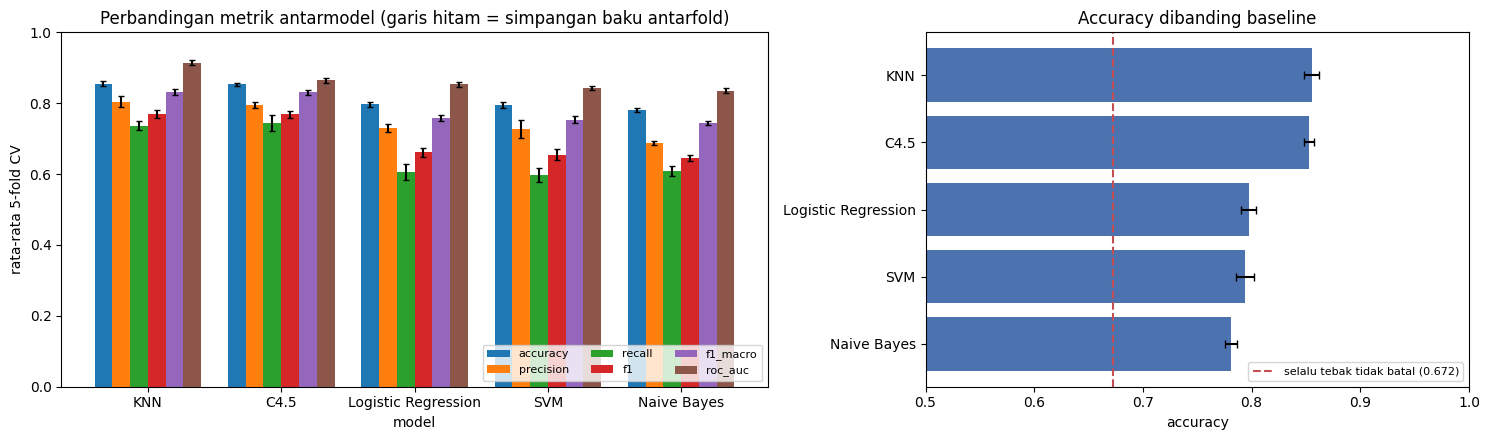

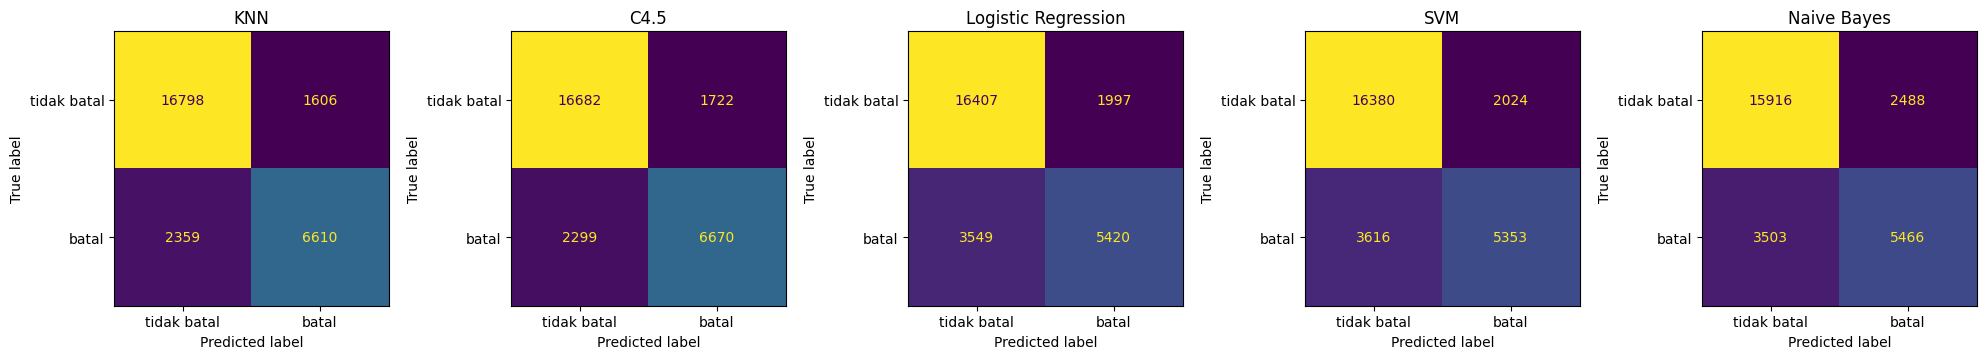

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={'width_ratios': [1.3, 1]})
final_table = final_results.set_index('model')
final_table[final_metrics].plot.bar(
    ax=axes[0], rot=0, width=0.8,
    yerr=final_table[[f'{metric}_std' for metric in final_metrics]].to_numpy().T, capsize=2,
)
axes[0].set_ylim(0, 1)
axes[0].set_ylabel('rata-rata 5-fold CV')
axes[0].set_title('Perbandingan metrik antarmodel (garis hitam = simpangan baku antarfold)')
axes[0].legend(loc='lower right', ncol=3, fontsize=8)

final_baseline = 1 - cv_y.mean()
axes[1].barh(final_results['model'], final_results['accuracy'], xerr=final_results['accuracy_std'],
             color='#4C72B0', capsize=3)
axes[1].axvline(final_baseline, color='#C44E52', linestyle='--', label=f'selalu tebak tidak batal ({final_baseline:.3f})')
axes[1].set_xlim(0.5, 1)
axes[1].invert_yaxis()
axes[1].set_xlabel('accuracy')
axes[1].set_title('Accuracy dibanding baseline')
axes[1].legend(loc='lower right', fontsize=8)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'model_comparison.png', dpi=150)
plt.show()

# Confusion matrix dari prediksi out-of-fold, setiap baris train.csv diprediksi tepat satu kali
fig, axes = plt.subplots(1, len(final_predictions), figsize=(4 * len(final_predictions), 3.6))
for ax, model_name in zip(axes, final_results['model']):
    y_true, predictions = final_predictions[model_name]
    ConfusionMatrixDisplay(confusion_matrix(y_true, predictions), display_labels=['tidak batal', 'batal']).plot(
        ax=ax, colorbar=False, values_format='d'
    )
    ax.set_title(model_name)
fig.tight_layout()
plt.show()

- KNN dan C4.5 berada di posisi teratas dengan F1 macro 0,832 ± 0,008 dan 0,830 ± 0,006. Selisih keduanya jauh lebih kecil daripada variasi antarfold. KNN unggul di tiga fold dan C4.5 di dua fold, sehingga keduanya dapat dianggap setara.
- Perbedaan terbesar keduanya ada pada roc_auc, yaitu 0,914 untuk KNN dan 0,865 untuk C4.5. Peluang KNN berasal dari 31 tetangga yang diberi bobot jarak sehingga nilainya halus. Peluang C4.5 hanya berasal dari proporsi kelas di leaf tempat booking itu jatuh sehingga nilainya lebih kasar.
- Logistic Regression dan SVM hampir sama, dengan F1 macro 0,759 dan 0,754. Hal ini wajar karena SVM terbaik memakai kernel linear, sehingga keduanya sama-sama mencari batas keputusan berupa garis lurus. SVM hanya dilatih dengan 1.000 baris per fold, tetapi hasilnya tetap dekat dengan Logistic Regression yang memakai seluruh train fold.
- Naive Bayes berada di posisi terakhir (F1 macro 0,744) dengan precision terendah (0,687), artinya paling sering salah menebak batal. Model ini menganggap setiap fitur saling independen, padahal ada fitur yang saling berkaitan, seperti is_returning_guest dan prior_completed_bookings.
- C4.5 dan KNN unggul karena keduanya bisa menangkap pola yang tidak linear. C4.5 memeriksa fitur secara berbeda di tiap cabang, sedangkan KNN mencari booking lain yang mirip di banyak fitur sekaligus. Model linear hanya memberi satu bobot untuk setiap fitur sehingga interaksi seperti ini sulit ditangkap.
- Semua model jauh di atas baseline 0,675, tetapi recall-nya hanya 0,60 sampai 0,74. Artinya sekitar 26 sampai 40% booking yang batal belum terdeteksi. Jika hotel lebih mementingkan antisipasi pembatalan, threshold prediksi dapat diturunkan untuk menaikkan recall dengan konsekuensi precision turun.
- Fold pertama memberi skor tertinggi untuk semua model. Kemungkinan sebagian karena konfigurasi tiap model dipilih dengan fold ini, sehingga angka di bagian masing-masing model sedikit optimistis. Rata-rata 5 fold di atas lebih dapat dipercaya untuk membandingkan model.

## Submission

In [51]:
sample_submission = pd.read_csv(DATA_DIR / 'sample_submission.csv')
test_X_raw = test_df.drop(columns=['id'])
assert test_X_raw.columns.tolist() == train_df.drop(columns=['id', 'is_canceled']).columns.tolist()
assert np.array_equal(test_df['id'].to_numpy(), sample_submission['id'].to_numpy())

# Setiap model menerima data test mentah dan memprosesnya dengan preprocessing miliknya sendiri
submission_predictors = {
    'c45': lambda raw: dtl_final_model.predict(dtl_preprocess(raw, dtl_final_rare)),
    'svm': lambda raw: svm_best_model.predict(svm_preprocessor.transform(raw)),
    'logreg': lambda raw: logreg_best_model.predict(logreg_preprocessor.transform(raw)),
    'knn': lambda raw: knn_final_model.predict(knn_final_preprocessor.transform(raw)),
    'naive_bayes': lambda raw: nb_final_model.predict(nb_transform(raw, nb_final_params, NB_MODE)),
}

submission_summary = []
for model_key, predict in submission_predictors.items():
    predictions = np.asarray(predict(test_X_raw)).astype(int)
    assert len(predictions) == len(test_df) and set(np.unique(predictions)) <= {0, 1}
    submission = pd.DataFrame({'id': test_df['id'], 'is_canceled': predictions})
    submission_path = OUTPUT_DIR / f'submission_{model_key}.csv'
    submission.to_csv(submission_path, index=False)
    submission_summary.append({
        'model': model_key, 'berkas': submission_path.name,
        'jumlah_baris': len(submission), 'proporsi_batal': predictions.mean(),
    })
pd.DataFrame(submission_summary)

,model,berkas,jumlah_baris,proporsi_batal
0,c45,submission_c45.csv,6844,0.304208
1,svm,submission_svm.csv,6844,0.262712
2,logreg,submission_logreg.csv,6844,0.262420
3,knn,submission_knn.csv,6844,0.294418
4,naive_bayes,submission_naive_bayes.csv,6844,0.284191
